# Used Cars Cost Prediction (India)
## 1. Business problem and data source
**Problem:** buyers and sellers of used cars in India struggle to know whether a listing is fairly priced. We build a model that predicts a fair price range and flags listings as over- or under-priced.
**Data:** CarDekho used-car listings (Kaggle, 'Vehicle dataset'). The target is the listing price in INR. Limitations: no city column, the data ends in 2020, and prices are listing prices, not confirmed transaction prices.

### 1.1 Load the data

In [1]:
# Cell 1: imports and load
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
RAW = "../data/raw/Car details v3.csv"
df_raw = pd.read_csv(RAW)
print("Raw shape:", df_raw.shape)
df_raw.head()

Raw shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


### 1.2 Data audit
Before modelling, we check data quality. Duplicates matter most: if identical rows land in both train and test, the model memorises them and the score is inflated.

In [2]:
# Cell 2: audit table
audit = {
    "rows_raw": len(df_raw),
    "exact_duplicates": int(df_raw.duplicated().sum()),
    "rows_after_dedupe": len(df_raw.drop_duplicates()),
    "year_min": int(df_raw.year.min()), "year_max": int(df_raw.year.max()),
    "price_min": int(df_raw.selling_price.min()), "price_max": int(df_raw.selling_price.max()),
    "median_price": int(df_raw.selling_price.median()),
}
print(pd.Series(audit))
print("\nMissing values:\n", df_raw.isna().sum()[lambda s: s > 0])

rows_raw                 8128
exact_duplicates         1202
rows_after_dedupe        6926
year_min                 1983
year_max                 2020
price_min               29999
price_max            10000000
median_price           450000
dtype: int64

Missing values:
 mileage      221
engine       221
max_power    215
torque       222
seats        221
dtype: int64


### 1.3 Are the missing values the same rows?
If the gaps in mileage, engine, max_power, torque and seats are the same rows, they are systematic (a scraping gap), not random, and this decides how we treat them.

In [3]:
# Cell 3: missing-value pattern
spec_cols = ["mileage", "engine", "max_power", "torque", "seats"]
miss = df_raw[spec_cols].isna()
print("Rows missing ANY spec:", miss.any(axis=1).sum())
print("Rows missing ALL specs:", miss.all(axis=1).sum())

Rows missing ANY spec: 222
Rows missing ALL specs: 215


### 1.4 Listings per car model
Later we validate by holding out whole car models, so the model is tested on cars it has never seen. This check shows whether we have enough listings per model for that.

In [4]:
# Cell 4: listings per model
df_raw["brand"] = df_raw["name"].str.split().str[0]
df_raw["model_key"] = df_raw["name"].str.split().str[:2].str.join(" ")
per_model = df_raw.drop_duplicates().model_key.value_counts()
print("Distinct brand+model:", per_model.size)
print(per_model.describe())
print("Models with < 5 listings:", (per_model < 5).sum())

Distinct brand+model: 210
count    210.000000
mean      32.980952
std       68.986717
min        1.000000
25%        3.000000
50%        8.000000
75%       32.000000
max      670.000000
Name: count, dtype: float64
Models with < 5 listings: 77


### 1.5 Findings
- **Duplicates:** 1,202 of 8,128 rows (14.8%) are exact duplicates. We remove them before any split, leaving 6,926 rows. There is no listing ID, so we assume identical rows are repeats. That is a limitation.
- **Price is heavily skewed:** median ₹4.5L, maximum ₹1 crore. This motivates modelling log(price) (justified in Section 3).
- **Missing specs are systematic, not random:** 215 of the 222 rows with any missing spec lack all five fields at once, so the gap looks like a source issue. We will test whether missingness relates to price before choosing an imputation.
- **Validation design:** a naive brand+model key gives 210 groups, and 77 of them (37%) have fewer than 5 listings. Grouped cross-validation is feasible, but the model key needs a better definition (Section 2).

## 2. Cleaning and feature parsing
Raw columns carry units inside strings and the car `name` packs brand, model and variant together. We turn them into clean numeric features and a **model key** that we will later use to keep whole car models out of the training folds.

**Decisions made in this section**
- Units are parsed to numbers. Engine is always in CC and power in bhp. Mileage is kmpl for most rows but **km/kg for 87 CNG/LPG cars**, so `fuel` stays in the model.
- A mileage or power of 0 is treated as missing, not as a real value.
- `torque` is dropped: it comes in inconsistent formats and mostly repeats engine and power.
- `age = 2020 − year`, because the data ends in 2020.
- A custom `model_key` replaces the naive "first two words" rule, which merged the Swift Dzire sedan into Swift and turned "Wagon R" into "Wagon".
- **Outlier rule:** a car with implied usage above 100,000 km per year is physically implausible and is removed (4 rows). High-priced cars and high-mileage taxis are kept because they are real.

In [5]:
# Cell 5: cleaning functions (defined inline so the notebook is self-contained)
import re
REF_YEAR = 2020                       # dataset ends in 2020, so we treat 2020 as "now"
MULTI_BRANDS = ["Land Rover", "Ashok Leyland"]            # brands written with two words
BRAND_FIX = {"Force": "Force Motors"}                     # one-word prefix -> full brand
MULTI_MODELS = ["Swift Dzire", "Wagon R", "Grand i10", "Alto 800", "Alto K10", "Santro Xing",
                "Indica Vista", "Vitara Brezza", "Innova Crysta", "Range Rover", "S Cross", "Grand Vitara"]

def split_brand_model(name):
    """Split 'Maruti Swift Dzire VDI' -> ('Maruti', 'Swift Dzire'); variant words are dropped."""
    s = name.strip()
    for b in MULTI_BRANDS:
        if s.startswith(b + " "):
            brand, rest = b, s[len(b) + 1:]
            break
    else:
        brand, _, rest = s.partition(" ")
        brand = BRAND_FIX.get(brand, brand)
    for m in MULTI_MODELS:                       # known two-word models first
        if rest.startswith(m):
            return brand, m
    toks = rest.split()
    if len(toks) > 1 and toks[0] == "New":       # 'New Safari', 'New C-Class'
        return brand, "New " + toks[1]
    if len(toks) > 1 and toks[1] == "Class":     # 'GLA Class', 'B Class'
        return brand, toks[0] + " Class"
    return brand, (toks[0] if toks else "")

def num(series, pattern):
    """Pull the leading number out of strings like '23.4 kmpl'; anything unparseable becomes NaN."""
    return pd.to_numeric(series.str.extract(pattern)[0], errors="coerce")

def clean(raw, dedupe=True):
    d = (raw.drop_duplicates() if dedupe else raw).reset_index(drop=True).copy()   # 1. remove exact duplicates first
    bm = d["name"].map(split_brand_model)
    d["brand"], d["model"] = bm.str[0], bm.str[1]
    d["model_key"] = d["brand"] + " " + d["model"]            # grouping key for leakage-safe CV
    d["mileage_val"] = num(d.mileage, r"^([\d.]+)")           # kmpl (km/kg for CNG/LPG)
    d["engine_cc"]   = num(d.engine,  r"^([\d.]+)")
    d["power_bhp"]   = num(d.max_power, r"^([\d.]+)")
    d.loc[d.mileage_val == 0, "mileage_val"] = np.nan         # a 0 kmpl car is a data gap
    d.loc[d.power_bhp == 0, "power_bhp"] = np.nan
    d["age"] = REF_YEAR - d.year
    d["km_per_year"] = d.km_driven / (d.age + 1)              # +1 so a 2020 car does not divide by 0
    d["owner"] = d.owner.replace({"Test Drive Car": "First Owner"})
    return d.drop(columns=["torque", "mileage", "engine", "max_power"])

df = clean(df_raw[df_raw.columns[:13]])    # only the 13 original columns (Cell 4 added helper columns to df_raw)
print("After de-dup and parsing:", df.shape)

After de-dup and parsing: (6926, 17)


In [6]:
# Cell 6: outlier rule - physically impossible usage, NOT 'expensive' or 'high-mileage taxi'
bad = df[df.km_per_year > 100_000]
print("Rows removed:", len(bad))
display(bad[["name", "year", "km_driven", "selling_price"]])
df = df[df.km_per_year <= 100_000].reset_index(drop=True)
print("Final shape:", df.shape)

Rows removed: 4


,name,year,km_driven,selling_price
1325,Mahindra XUV500 W7,2020,120000,830000
1646,Mahindra XUV500 W6 2WD,2012,1500000,500000
2131,Maruti Celerio X ZXI,2020,120000,250000
3161,Hyundai i20 Asta 1.2,2007,2360457,550000


Final shape: (6922, 17)


In [7]:
# Cell 7: sanity checks (the notebook fails loudly if the cleaning is wrong)
assert df.duplicated().sum() == 0
assert (df.age >= 0).all() and df.selling_price.min() > 0
print("Unique model keys:", df.model_key.nunique())
print("Models with < 5 listings:", (df.model_key.value_counts() < 5).sum())
print("\nMissing values after parsing:\n", df.isna().sum()[lambda s: s > 0])
df.describe().T

Unique model keys: 218
Models with < 5 listings: 79

Missing values after parsing:
 seats          208
mileage_val    223
engine_cc      208
power_bhp      209
dtype: int64


,count,mean,std,min,25%,50%,75%,max
year,6922.0,2013.419532,4.077165,1983.0,2011.000000,2014.000000,2017.000000,2020.0
selling_price,6922.0,517261.877925,519893.457931,29999.0,250000.000000,400000.000000,633500.000000,10000000.0
km_driven,6922.0,73446.055764,48554.496519,1.0,40000.000000,70000.000000,100000.000000,577414.0
seats,6714.0,5.434316,0.984123,2.0,5.000000,5.000000,5.000000,14.0
mileage_val,6699.0,19.510004,3.947796,9.0,16.800000,19.490000,22.540000,42.0
engine_cc,6714.0,1430.767799,493.434805,624.0,1197.000000,1248.000000,1498.000000,3604.0
power_bhp,6713.0,87.752599,31.716550,32.8,67.100000,81.830000,100.000000,400.0
age,6922.0,6.580468,4.077165,0.0,3.000000,6.000000,9.000000,37.0
km_per_year,6922.0,10570.466745,6713.515387,0.1,6153.846154,9166.666667,13333.333333,70000.0


## 3. Exploratory analysis
We look for what drives price, and for traps that would mislead a model. Four questions: are the missing specs random, what shape is the target, how fast do cars lose value, and what does mileage really do?

In [8]:
# Cell 8: is missingness random? (decides imputation vs dropping)
from scipy.stats import mannwhitneyu
df["specs_missing"] = df[["engine_cc", "power_bhp", "seats"]].isna().any(axis=1)
display(df.groupby("specs_missing").agg(rows=("selling_price", "size"), median_price=("selling_price", "median"),
                                        median_year=("year", "median"), median_km=("km_driven", "median")))
stat, p = mannwhitneyu(df.loc[df.specs_missing, "selling_price"], df.loc[~df.specs_missing, "selling_price"])
print(f"Mann-Whitney p-value (price: missing vs present): {p:.2e}")
has_specs = df.groupby("model_key")["engine_cc"].apply(lambda s: s.notna().any())
print("Share of missing-spec rows whose model has specs elsewhere:",
      round(df.loc[df.specs_missing, "model_key"].map(has_specs).mean(), 3))

,rows,median_price,median_year,median_km
specs_missing,,,,
False,6713,420000.0,2014.0,68089.0
True,209,175000.0,2008.0,90000.0


Mann-Whitney p-value (price: missing vs present): 2.83e-50
Share of missing-spec rows whose model has specs elsewhere: 0.904


**Insight:** the 209 rows with missing specs have a median price of ₹1.75L against ₹4.2L for the rest, and they are older (2008 vs 2014). Missingness is therefore **not random**. Dropping them would remove the cheapest segment, and filling with the global mean would misprice them. Since 90% belong to a model that has specs elsewhere, our first idea was to impute within model and fuel. Section 5 tests that idea against simple median imputation (done inside each CV fold, to avoid leakage) and keeps missing-indicator features.

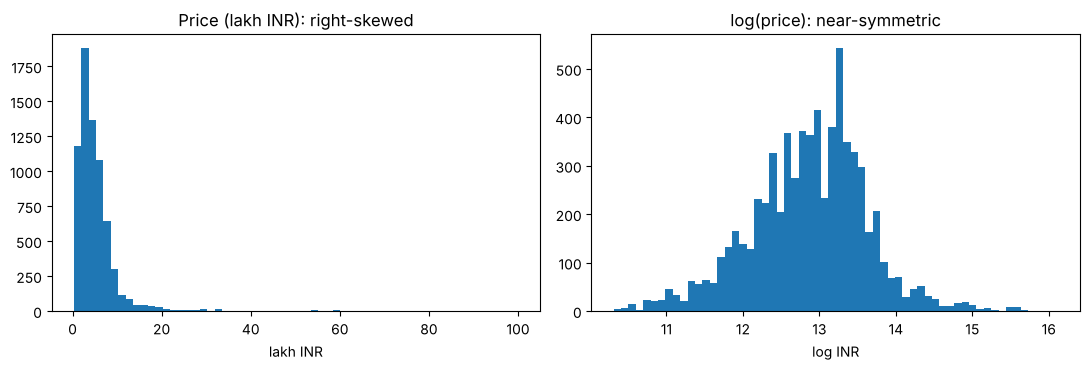

Skewness  raw: 5.57 | log: -0.16


In [9]:
# Cell 9: target distribution and the log transform
from scipy.stats import skew
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df.selling_price / 1e5, bins=60); ax[0].set_title("Price (lakh INR): right-skewed"); ax[0].set_xlabel("lakh INR")
ax[1].hist(np.log(df.selling_price), bins=60); ax[1].set_title("log(price): near-symmetric"); ax[1].set_xlabel("log INR")
plt.tight_layout(); plt.savefig("../reports/figures/price_distribution.png", dpi=120); plt.show()
print("Skewness  raw:", round(skew(df.selling_price), 2), "| log:", round(skew(np.log(df.selling_price)), 2))

**Insight:** raw price has skewness 5.6, because a few luxury cars stretch the tail, and log-price has −0.16. We model **log(price)** for two reasons. A ₹50,000 error means very different things on a ₹1L car and a ₹50L car, and depreciation works in percentages (a car loses roughly a fixed share per year, not a fixed rupee amount). Predictions are converted back with `exp()`, and we report errors in rupees and in percent.

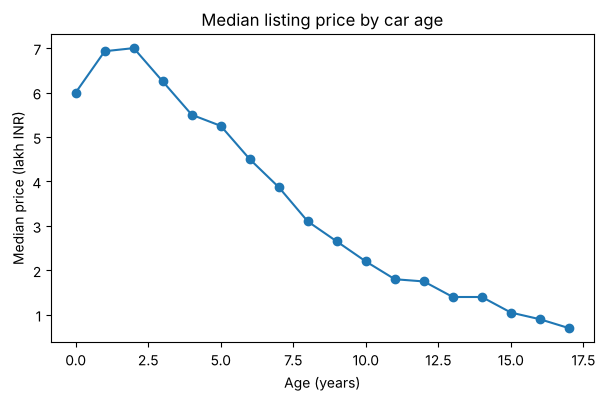

,brand,n,min_age,max_age,naive_annual_dep_%
6,Renault,206,1,9,-0.3
9,Volkswagen,174,0,12,8.5
4,Mahindra,721,0,37,9.5
2,Honda,362,0,18,11.9
8,Toyota,357,0,20,12.5
5,Maruti,2164,0,29,12.5
3,Hyundai,1266,0,21,12.9
0,Chevrolet,216,3,15,13.2
1,Ford,361,0,17,13.9
7,Tata,647,0,21,14.1


In [10]:
# Cell 10: depreciation by age, and a naive per-brand estimate (we will test its weakness next)
import matplotlib.pyplot as plt
med = df.groupby("age").selling_price.agg(median="median", n="size")
med = med[med.n >= 30]                                  # ignore ages with too few cars
plt.figure(figsize=(7, 4)); plt.plot(med.index, med["median"] / 1e5, marker="o")
plt.xlabel("Age (years)"); plt.ylabel("Median price (lakh INR)"); plt.title("Median listing price by car age")
plt.savefig("../reports/figures/price_by_age.png", dpi=120); plt.show()

rows = []
for b, g in df.groupby("brand"):
    if len(g) >= 150:
        slope = np.polyfit(g.age, np.log(g.selling_price), 1)[0]       # slope of log-price per year of age
        rows.append((b, len(g), g.age.min(), g.age.max(), round((1 - np.exp(slope)) * 100, 1)))
brand_dep = pd.DataFrame(rows, columns=["brand", "n", "min_age", "max_age", "naive_annual_dep_%"]).sort_values("naive_annual_dep_%")
display(brand_dep)

In [11]:
# Cell 10b: evidence for the insight below - the age curve and the Renault slope are mix effects
young, new = df[df.age.isin([1, 2])], df[df.age == 0]
print("Maruti share of listings   age 0: %.0f%% | ages 1-2: %.0f%%" % (100 * (new.brand == "Maruti").mean(),
                                                                        100 * (young.brand == "Maruti").mean()))
both = set(new.model_key) & set(young.model_key)
print("Car models present at both age 0 and ages 1-2:", len(both))
display(df[df.model_key.isin(both) & (df.age <= 2)].groupby("age").selling_price.agg(median_price="median", rows="size"))
ren = df[df.brand == "Renault"]
rows = []
for m in ["KWID", "Duster"]:
    g = ren[ren.model == m]
    rows.append((m, len(g), g.age.min(), g.age.max(), round((1 - np.exp(np.polyfit(g.age, np.log(g.selling_price), 1)[0])) * 100, 1)))
display(pd.DataFrame(rows, columns=["Renault model", "n", "min_age", "max_age", "annual_dep_%"]))

Maruti share of listings   age 0: 46% | ages 1-2: 30%
Car models present at both age 0 and ages 1-2: 32


,median_price,rows
age,,
0,600000.0,57
1,610000.0,203
2,620000.0,327


,Renault model,n,min_age,max_age,annual_dep_%
0,KWID,99,1,5,8.2
1,Duster,71,2,8,11.1


**Insight (and a warning about it):** the median price *rises* from age 0 to age 2 (about ₹6.0L to ₹7.0L) before falling. That is not appreciation: Maruti makes up 46% of the age-0 listings against about 30% at ages 1–2, and among the car models that appear at both ages the median price is flat (about ₹6.0L–₹6.2L from age 0 to 2). The curve mixes car type with age. The per-brand slopes have the same problem: Renault shows about 0% depreciation only because its young cars are mostly the cheap KWID (ages 1–5) while its older cars are mostly the pricier Duster (ages 2–8); within each model the slope is about 8% (KWID) and 11% (Duster) a year. **Raw brand comparisons confound age with which models and variants a brand sells.** The next cells separate them.

In [12]:
# Cell 11: mileage looks like it RAISES price - why?
band = df[df.age.between(5, 7)].copy()                  # hold age roughly constant
band["km_quartile"] = pd.qcut(band.km_driven, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
display(band.groupby("km_quartile", observed=True).agg(median_price=("selling_price", "median"),
        diesel_share=("fuel", lambda s: (s == "Diesel").mean()), rows=("fuel", "size")).round(2))

,median_price,diesel_share,rows
km_quartile,,,
Q1 low,420000.0,0.34,521
Q2,450000.0,0.64,399
Q3,465000.0,0.79,457
Q4 high,500000.0,0.91,447


**Insight (a confounding trap):** among 5–7-year-old cars, the *highest*-mileage quartile has the *highest* median price (₹5.0L vs ₹4.2L). Diesel share explains why: it rises from 34% to 91% across the quartiles, and diesel cars are driven more and priced higher. Mileage itself isn't raising prices. A naive plot of price against km would give a wrong story.

In [13]:
# Cell 12: depreciation WITHIN a model (model fixed effects, by de-meaning each variable within model_key)
d = df[df.groupby("model_key")["model_key"].transform("size") >= 10].copy()    # models with >= 10 listings
d["log_price"] = np.log(d.selling_price); d["km_10k"] = d.km_driven / 10_000
d["is_diesel"] = (d.fuel == "Diesel").astype(float); d["is_auto"] = (d.transmission == "Automatic").astype(float)
d["not_first_owner"] = (d.owner != "First Owner").astype(float)
cols = ["age", "km_10k", "is_diesel", "is_auto", "not_first_owner"]
dm = d[cols + ["log_price"]] - d.groupby("model_key")[cols + ["log_price"]].transform("mean")   # remove model identity
beta, *_ = np.linalg.lstsq(dm[cols].values, dm["log_price"].values, rcond=None)
effects = pd.DataFrame({"effect_on_price_%": ((np.exp(beta) - 1) * 100).round(1)}, index=cols)
print("Rows:", len(d), "| models:", d.model_key.nunique()); display(effects)

Rows: 6540 | models: 104


,effect_on_price_%
age,-9.8
km_10k,-0.9
is_diesel,13.6
is_auto,11.3
not_first_owner,-7.7


**Insight:** comparing cars *of the same model*, each extra year of age lowers price by about **9.8%**, and each extra 10,000 km lowers it by only about **0.9%** once age is held fixed. Diesel adds about 13.6%, an automatic gearbox adds about 11.3%, and a non-first owner costs about 7.7%. **Age matters far more than mileage.** These are descriptive associations within models, not causal effects, and the models with few listings are excluded.

## 4. Validation design and baselines
Before fitting anything strong we decide **how we will judge it**. We lock away a final test set made of whole car models the model never sees, tune only on the development set, and compare every model with simple baselines. We also measure how much a careless split would flatter the results.

**Decisions made in this section**
- **Final test set:** 20% of the car models, locked away until the very end.
- **Development validation:** `StratifiedGroupKFold`, grouped by `model_key` (a model never sits on both sides of a split) and stratified by price band (cheap and expensive cars stay balanced).
- **Metrics:** RMSE and R² on log-price (approximate relative error), MAE in rupees (easy to read), and **MedAPE**, the median absolute percentage error (robust to luxury outliers, and the number a buyer cares about).
- **Baselines:** global median, median by age, and a linear model on age and log-mileage.

In [14]:
# Cell 13: target, features, and the locked-away final test set
from sklearn.model_selection import StratifiedGroupKFold
df["log_price"] = np.log(df.selling_price)                       # target (see Section 3)
df["log_km"] = np.log1p(df.km_driven)                            # log of mileage; 1p guards km = 0
NUM = ["age", "km_driven", "engine_cc", "power_bhp", "seats", "mileage_val"]
CAT = ["fuel", "transmission", "owner", "seller_type", "brand"]
price_band = pd.qcut(df.selling_price, 5, labels=False)          # keeps cheap/expensive cars balanced across folds
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
dev_idx, test_idx = next(outer.split(df, price_band, groups=df.model_key))   # first fold = 20% test
dev, test = df.iloc[dev_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
print("Development rows:", len(dev), "| Final test rows:", len(test), f"({len(test)/len(df):.1%})")
print("Models shared between dev and test:", len(set(dev.model_key) & set(test.model_key)))
print("Median price  dev:", dev.selling_price.median(), "| test:", test.selling_price.median())

Development rows: 5530 | Final test rows: 1392 (20.1%)
Models shared between dev and test: 0
Median price  dev: 400000.0 | test: 415000.0


In [15]:
# Cell 14: metrics and a cross-validation helper (everything is scored in RUPEE terms after exp())
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone
def score(y_log_true, y_log_pred):
    p_true, p_pred = np.exp(y_log_true), np.exp(y_log_pred)
    return {"RMSE_log": np.sqrt(mean_squared_error(y_log_true, y_log_pred)),
            "R2_log": r2_score(y_log_true, y_log_pred),
            "MAE_INR": mean_absolute_error(p_true, p_pred),
            "MedAPE_%": 100 * np.median(np.abs(p_pred - p_true) / p_true)}

def cv_eval(model, data, features, cv):
    """Grouped CV on `data`. Returns mean and std of each metric, plus out-of-fold predictions."""
    X, y, g = data[features], data["log_price"], data["model_key"]
    bands = pd.qcut(data.selling_price, 5, labels=False)
    rows, oof = [], np.zeros(len(data))
    for tr, va in cv.split(X, bands, groups=g):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])           # fit on training folds only
        oof[va] = m.predict(X.iloc[va])
        rows.append(score(y.iloc[va].values, oof[va]))
    r = pd.DataFrame(rows)
    return r.mean(), r.std(), oof

cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)   # development CV, grouped by model

In [16]:
# Cell 15: baseline ladder (grouped CV on the development set)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.base import BaseEstimator, RegressorMixin

class AgeMedian(BaseEstimator, RegressorMixin):
    """Predict the median log-price of cars of the same age (ages above 20 are pooled)."""
    def fit(self, X, y):
        a = X["age"].clip(upper=20)
        self.table_ = pd.Series(np.asarray(y), index=a.values).groupby(level=0).median()
        self.global_ = float(np.median(y)); return self
    def predict(self, X):
        return X["age"].clip(upper=20).map(self.table_).fillna(self.global_).values

baselines = {"B0 global median": (DummyRegressor(strategy="median"), ["age"]),
             "B1 median by age": (AgeMedian(), ["age"]),
             "B2 linear: age + log km": (LinearRegression(), ["age", "log_km"])}
res = {}
for name, (m, feats) in baselines.items():
    mean, std, _ = cv_eval(m, dev, feats, cv_group)
    res[name] = mean
baseline_table = pd.DataFrame(res).T.round(3)
baseline_table

,RMSE_log,R2_log,MAE_INR,MedAPE_%
B0 global median,0.769,-0.004,277822.994,42.857
B1 median by age,0.528,0.526,204502.088,28.954
B2 linear: age + log km,0.528,0.526,205299.901,28.671


**Insight:** knowing only a car's age cuts the typical error from about 43% to 29% (R² on log-price from 0 to 0.53). Adding mileage to a linear model changes almost nothing, which is consistent with Section 3, where 10,000 km cost only about 1% once age is held fixed. These baselines are the bar every later model has to clear: **RMSE_log 0.53, MedAPE about 29%**.

In [17]:
# Cell 16: how much does a careless split flatter the score? (same model, same data, three validation designs)
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import KFold

prep = ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM),     # imputer is fitted inside each fold
                          ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
rf = Pipeline([("prep", prep), ("rf", RandomForestRegressor(n_estimators=150, random_state=0, n_jobs=-1))])

# Duplicates kept, restricted to the same car models as the dev set so that only the duplicates differ
leaky = clean(df_raw[df_raw.columns[:13]], dedupe=False)
leaky = leaky[leaky.km_per_year <= 100_000]
leaky = leaky[leaky.model_key.isin(dev.model_key)].reset_index(drop=True)
leaky["log_price"] = np.log(leaky.selling_price)

def eval_splits(data, splits):
    X, y = data[NUM + CAT], data["log_price"]; out = []
    for tr, va in splits:
        m = clone(rf).fit(X.iloc[tr], y.iloc[tr]); out.append(score(y.iloc[va].values, m.predict(X.iloc[va])))
    return pd.DataFrame(out).mean()

kf = KFold(5, shuffle=True, random_state=1)
bands = pd.qcut(dev.selling_price, 5, labels=False)
leak_demo = pd.DataFrame({
    "1) Duplicates kept, random split": eval_splits(leaky, kf.split(leaky)),
    "2) De-duplicated, random split": eval_splits(dev, kf.split(dev)),
    "3) De-duplicated, grouped by model": eval_splits(dev, cv_group.split(dev, bands, groups=dev.model_key)),
}).T.round(3)
leak_demo

,RMSE_log,R2_log,MAE_INR,MedAPE_%
"1) Duplicates kept, random split",0.215,0.934,66227.942,9.821
"2) De-duplicated, random split",0.236,0.906,78907.180,12.509
"3) De-duplicated, grouped by model",0.332,0.810,116933.980,19.056


**Insight: the same random forest on the same cars gives three very different scores.** Keeping duplicates and splitting randomly gives R² about 0.93 and a typical error near 10%, because the model is tested on rows it has already seen. Removing duplicates drops that to about 0.91 / 12.5%. Holding out whole car models gives about **0.81 / 19%**, which is what the model can do on a model it has never priced. Many submissions report the first number. We report the third and explain the difference. The first two describe a typical repeat listing, and the third is the stress test.

## 5. Models
We now compare model families on the **development set only**; the final test set stays locked. All preprocessing (median imputation with missing-indicators, scaling, one-hot encoding) lives **inside** each pipeline, so it is learned from the training folds only and cannot leak.

**Decisions made in this section**
- **Candidates:** regularised linear models (Ridge, ElasticNet), random forest, and three gradient-boosting libraries (HistGradientBoosting, XGBoost, LightGBM).
- **Features:** age, log-mileage, engine, power, seats, mileage, fuel, transmission, owner, seller type and brand. The model identity (`model_key`) is deliberately **not** a feature: it is only the grouping key for validation.
- **Two validation regimes for every model:** *grouped by car model* (the stress test: pricing a model never seen) and *random on de-duplicated data* (a typical repeat listing, where the model has been seen).
- **Selection rule, stated here and applied mechanically below:** take the best grouped-CV RMSE_log, keep every model within one fold-standard-deviation of it (one-standard-error rule), and among those choose the best typical-listing error.

In [18]:
# Cell 17: features and a leakage-safe pipeline factory
for part in (df, dev, test):                                      # log versions of the two skewed spec columns (helps linear models)
    part["log_engine"] = np.log(part.engine_cc)
    part["log_power"] = np.log(part.power_bhp)
NUM_M = ["age", "log_km", "log_engine", "log_power", "seats", "mileage_val"]
CAT_M = ["fuel", "transmission", "owner", "seller_type", "brand"]
FEATS = NUM_M + CAT_M                                             # model identity (model_key) is NOT a feature: it is only the grouping key

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_pipe(model, scale=False):
    """Preprocessing + model in ONE pipeline, so imputation/scaling/encoding are learned from training folds only."""
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),      # fill gaps, and flag which were gaps
                    ("scale", StandardScaler() if scale else "passthrough")])
    cols = ColumnTransformer([("num", num, NUM_M),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_M)])
    return Pipeline([("cols", cols), ("model", model)])

In [19]:
# Cell 18: candidate models, each scored in two regimes
from sklearn.linear_model import RidgeCV, ElasticNetCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

candidates = {
    "Ridge": make_pipe(RidgeCV(alphas=np.logspace(-2, 2, 15)), scale=True),
    "ElasticNet": make_pipe(ElasticNetCV(l1_ratio=[.2, .5, .8], alphas=np.logspace(-4, -1, 12), cv=5, max_iter=5000), scale=True),
    "RandomForest": make_pipe(RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=0)),
    "HistGradientBoosting": make_pipe(HistGradientBoostingRegressor(learning_rate=0.05, max_iter=400, max_leaf_nodes=15, l2_regularization=1.0, random_state=0)),
    "XGBoost": make_pipe(XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                                      min_child_weight=3, reg_lambda=2.0, random_state=0, n_jobs=-1)),
    "LightGBM": make_pipe(LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                                        colsample_bytree=0.8, min_child_samples=15, reg_lambda=2.0, random_state=0, n_jobs=-1, verbose=-1)),
}
seen_cv = KFold(5, shuffle=True, random_state=1)                  # regime 2: random split of de-duplicated data (typical repeat listing)

def both_regimes(model):
    g_mean, g_std, _ = cv_eval(model, dev, FEATS, cv_group)       # regime 1: grouped by car model (stress test)
    rows = []
    for tr, va in seen_cv.split(dev):
        m = clone(model).fit(dev[FEATS].iloc[tr], dev.log_price.iloc[tr])
        rows.append(score(dev.log_price.iloc[va].values, m.predict(dev[FEATS].iloc[va])))
    s = pd.DataFrame(rows).mean()
    return {"grouped_RMSE_log": g_mean["RMSE_log"], "grouped_std": g_std["RMSE_log"], "grouped_MedAPE_%": g_mean["MedAPE_%"],
            "grouped_R2": g_mean["R2_log"], "seen_MedAPE_%": s["MedAPE_%"], "seen_R2": s["R2_log"]}

results = pd.DataFrame({name: both_regimes(m) for name, m in candidates.items()}).T
results.round(3)

,grouped_RMSE_log,grouped_std,grouped_MedAPE_%,grouped_R2,seen_MedAPE_%,seen_R2
Ridge,0.280,0.018,16.824,0.866,15.141,0.888
ElasticNet,0.280,0.019,16.865,0.866,15.135,0.888
RandomForest,0.311,0.050,18.148,0.832,12.070,0.913
HistGradientBoosting,0.292,0.037,16.951,0.852,11.971,0.915
XGBoost,0.289,0.031,16.887,0.856,12.270,0.916
LightGBM,0.294,0.038,17.649,0.851,11.866,0.916


**Insight: the best model depends on the question.** On unseen car models, Ridge and ElasticNet are best (RMSE_log 0.280, typical error about 17%), XGBoost, HistGradientBoosting and LightGBM are close behind (0.289–0.294), and the random forest is worst and least stable (0.311, fold standard deviation 0.050). With fold standard deviations of 0.02–0.04, everything except the forest is statistically indistinguishable on this test. On a typical repeat listing the order flips: boosting and the forest reach about 12% median error against about 15% for the linear models. Linear models extrapolate well to unseen models but cannot capture the interactions that matter once a model has been seen.

In [20]:
# Cell 19: the selection rule, applied mechanically
best_name = results.grouped_RMSE_log.idxmin()
threshold = results.loc[best_name, "grouped_RMSE_log"] + results.loc[best_name, "grouped_std"]       # one-standard-error rule
shortlist = results[results.grouped_RMSE_log <= threshold]
chosen = shortlist["seen_MedAPE_%"].idxmin()
print(f"Best on the stress test: {best_name} (RMSE_log {results.loc[best_name, 'grouped_RMSE_log']:.3f}); threshold = {threshold:.3f}")
print("Shortlist (statistically indistinguishable on the stress test):", list(shortlist.index))
print("Chosen (best typical-listing MedAPE among the shortlist):", chosen)

Best on the stress test: Ridge (RMSE_log 0.280); threshold = 0.298
Shortlist (statistically indistinguishable on the stress test): ['Ridge', 'ElasticNet', 'HistGradientBoosting', 'XGBoost', 'LightGBM']
Chosen (best typical-listing MedAPE among the shortlist): LightGBM


**Decision:** the rule picks **LightGBM**. Its edge over HistGradientBoosting on the typical-listing error is about 0.1 percentage points, which is not a meaningful gap; we take LightGBM because it supports native quantile regression (for the prediction intervals in the next sections) and works directly with SHAP. The final test set has not been touched.

In [21]:
# Cell 20: did our model-aware imputation idea (Section 3) actually help?
from sklearn.base import BaseEstimator, TransformerMixin
class ModelAwareFill(BaseEstimator, TransformerMixin):
    """Our first idea: fill missing specs from the same model+fuel, falling back to brand+fuel, then fuel, then global."""
    SPECS = ["log_engine", "log_power", "seats", "mileage_val"]
    LEVELS = [["model_key", "fuel"], ["brand", "fuel"], ["fuel"]]
    def fit(self, X, y=None):
        self.tables_ = [(lv, X.groupby(lv)[self.SPECS].median()) for lv in self.LEVELS]
        self.global_ = X[self.SPECS].median(); return self
    def transform(self, X):
        X = X.copy()
        for lv, tab in self.tables_:
            idx = pd.MultiIndex.from_frame(X[lv]) if len(lv) > 1 else pd.Index(X[lv[0]])
            fill = tab.reindex(idx); fill.index = X.index
            for c in self.SPECS: X[c] = X[c].fillna(fill[c])
        for c in self.SPECS: X[c] = X[c].fillna(self.global_[c])
        return X

def with_fill(model, scale=False):
    return Pipeline([("fill", ModelAwareFill()), ("rest", make_pipe(model, scale))])

abl = {}
for name, plain, aware in [("Ridge", candidates["Ridge"], with_fill(RidgeCV(alphas=np.logspace(-2, 2, 15)), scale=True)),
                           ("LightGBM", candidates["LightGBM"], with_fill(clone(candidates["LightGBM"].named_steps["model"])))]:
    feats_aware = FEATS + ["model_key"]                           # the aware filler needs the model key
    m_plain, _, _ = cv_eval(plain, dev, FEATS, cv_group)
    m_aware, _, _ = cv_eval(aware, dev, feats_aware, cv_group)
    abl[name] = {"median fill: RMSE_log": m_plain["RMSE_log"], "model-aware fill: RMSE_log": m_aware["RMSE_log"],
                 "median fill: MedAPE_%": m_plain["MedAPE_%"], "model-aware fill: MedAPE_%": m_aware["MedAPE_%"]}
pd.DataFrame(abl).T.round(4)

,median fill: RMSE_log,model-aware fill: RMSE_log,median fill: MedAPE_%,model-aware fill: MedAPE_%
Ridge,0.2800,0.2796,16.8242,16.8645
LightGBM,0.2943,0.2964,17.6495,17.0875


**Insight: our own idea did not help.** In Section 3 we proposed filling missing specs from the same model and fuel. Against plain median filling the difference is within noise (Ridge RMSE_log 0.2796 vs 0.2800, LightGBM 0.2964 vs 0.2943, against fold standard deviations of 0.02–0.04), and it is not consistently better on MedAPE either. The simpler pipeline stays: median filling plus missing-indicator columns, which keep the "old and cheap" signal found in Section 3. Reporting a reasonable idea that did not pay off is part of the evidence.

In [22]:
# Cell 21: how complex should the trees be?
rows = {}
for leaves in [4, 8, 15, 31]:
    m = make_pipe(LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=leaves, subsample=0.8, subsample_freq=1,
                                colsample_bytree=0.8, min_child_samples=15, reg_lambda=2.0, random_state=0, n_jobs=-1, verbose=-1))
    r = both_regimes(m)
    rows[f"LightGBM, {leaves} leaves"] = {"grouped_RMSE_log": r["grouped_RMSE_log"], "grouped_MedAPE_%": r["grouped_MedAPE_%"], "seen_MedAPE_%": r["seen_MedAPE_%"]}
pd.DataFrame(rows).T.round(3)

,grouped_RMSE_log,grouped_MedAPE_%,seen_MedAPE_%
"LightGBM, 4 leaves",0.287,16.852,13.503
"LightGBM, 8 leaves",0.288,16.773,12.307
"LightGBM, 15 leaves",0.294,17.649,11.866
"LightGBM, 31 leaves",0.302,17.832,11.631


**Insight: complexity trades one regime against the other.** Shallower trees do slightly better on unseen models (RMSE_log 0.287 with 4 leaves against 0.302 with 31) but clearly worse on repeat listings (13.5% against 11.6% median error). We keep **15 leaves**: it is the most complex setting that still sits inside the one-standard-deviation band of the stress test (0.298), so it takes the best typical-listing result without giving up robustness. Selection used the same grouped folds as the reporting, so the numbers are slightly optimistic; the locked test set is the honest check.

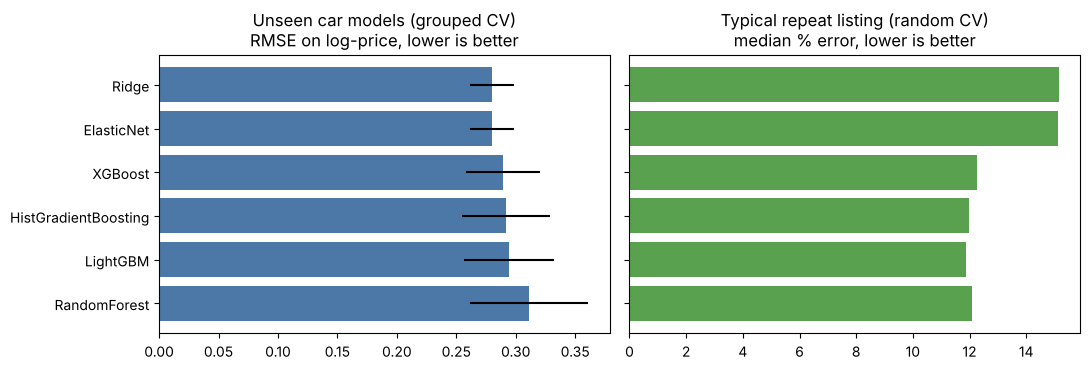

In [23]:
# Cell 22: comparison figure
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
order = results.sort_values("grouped_RMSE_log").index
ax[0].barh(order, results.loc[order, "grouped_RMSE_log"], xerr=results.loc[order, "grouped_std"], color="#4C78A8")
ax[0].set_title("Unseen car models (grouped CV)\nRMSE on log-price, lower is better"); ax[0].invert_yaxis()
ax[1].barh(order, results.loc[order, "seen_MedAPE_%"], color="#59A14F")
ax[1].set_title("Typical repeat listing (random CV)\nmedian % error, lower is better")
plt.tight_layout(); plt.savefig("../reports/figures/model_comparison.png", dpi=120); plt.show()

**Section 5 summary:** model = LightGBM (15 leaves, 500 trees, learning rate 0.03) inside the leakage-safe pipeline. Next we look at *where* it is wrong (error analysis), explain it with SHAP, and build the prediction intervals and the Deal Score.

## 6. Prediction intervals
A single point prediction is not enough for a buyer or seller: knowing a car is expected to cost Rs 5.0L is very different if the market spread is Rs 4.7L-Rs 5.3L versus Rs 3.5L-Rs 7.0L.

Standard prediction intervals rely on Gaussian or homoscedastic assumptions that fail on skewed used-car prices. Instead we use **Conformalized Quantile Regression (CQR)**:
- Fit base quantile regressors at alpha_lo = 0.05 and alpha_hi = 0.95 (nominal 90% band).
- Hold out a **calibration set** split strictly by `model_key` from training folds (never touching the locked test set).
- Compute conformity scores $E_i = \max(\hat{q}_{lo}(x_i) - y_i,\; y_i - \hat{q}_{hi}(x_i))$.
- Find $Q_{1-\alpha}(E)$ at level $\lceil(n+1)(1-\alpha)\rceil / n$.
- Calibrated intervals $[\hat{q}_{lo}(x) - Q_{1-\alpha},\; \hat{q}_{hi}(x) + Q_{1-\alpha}]$ have exact finite-sample marginal coverage under exchangeability, no distributional assumption.

**Mondrian (group-conditional) CQR** computes a separate $Q_{1-\alpha}^{(g)}$ for each predicted price band, without using true price at prediction time.

**Median-width formula used in all tables:**
$$\text{med\_width\_\%} = 100 \times \operatorname{median}_i\!\left[\frac{\exp(\text{upper}_i) - \exp(\text{lower}_i)}{\exp(y^{\text{true}}_i)}\right]$$
denominator is the **true** listing price in INR.

**Decisions in this section:** D23-D29 (docs/decision_log.md).

In [24]:
# Cell 23: CQR helpers. The conformal classes live in src/conformal.py, so the saved models can be loaded outside this notebook
import sys
sys.path.insert(0, "..")                       # repo root, so `src` can be imported from notebooks/
from src.conformal import compute_cqr_adjustment, MondrianCQR, FuelMondrianCQR, LocallyAdaptiveCQR

def interval_metrics(y_log_true, lower_log, upper_log):
    # coverage %, mean log-width, median %-width over true price, Winkler score alpha=0.10
    y  = np.asarray(y_log_true)
    lo = np.asarray(lower_log)
    hi = np.asarray(upper_log)
    covered       = (y >= lo) & (y <= hi)
    width_log     = hi - lo
    pct_width     = 100.0 * (np.exp(hi) - np.exp(lo)) / np.exp(y)
    alpha         = 0.10
    score         = (width_log
                     + (2.0 / alpha) * (lo - y) * (y < lo)
                     + (2.0 / alpha) * (y - hi) * (y > hi))
    return {"coverage_%":    round(float(np.mean(covered)) * 100, 2),
            "mean_width_log": round(float(np.mean(width_log)), 3),
            "med_width_%":    round(float(np.median(pct_width)), 1),
            "interval_score": round(float(np.mean(score)), 3)}


print("Imported from src/conformal.py: compute_cqr_adjustment, MondrianCQR, FuelMondrianCQR, LocallyAdaptiveCQR")
print("med_width_% = 100 x median_i { (exp(hi_i) - exp(lo_i)) / exp(y_true_i) }")

Imported from src/conformal.py: compute_cqr_adjustment, MondrianCQR, FuelMondrianCQR, LocallyAdaptiveCQR
med_width_% = 100 x median_i { (exp(hi_i) - exp(lo_i)) / exp(y_true_i) }


In [25]:
# Cell 24: all four methods in both regimes
from sklearn.linear_model import QuantileRegressor
from lightgbm import LGBMRegressor

# --- pipeline definitions ---
qr_lo  = make_pipe(QuantileRegressor(quantile=0.05, alpha=0.1, solver="highs"), scale=True)
qr_hi  = make_pipe(QuantileRegressor(quantile=0.95, alpha=0.1, solver="highs"), scale=True)

lgb_lo = make_pipe(LGBMRegressor(objective="quantile", alpha=0.05, num_leaves=15,
                   n_estimators=500, learning_rate=0.03, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.8, min_child_samples=15, reg_lambda=2.0,
                   random_state=0, n_jobs=-1, verbose=-1))
lgb_hi = make_pipe(LGBMRegressor(objective="quantile", alpha=0.95, num_leaves=15,
                   n_estimators=500, learning_rate=0.03, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.8, min_child_samples=15, reg_lambda=2.0,
                   random_state=0, n_jobs=-1, verbose=-1))


def evaluate_all_cv(split_regime, is_grouped=True, inner_seed=42):
    # OOF intervals for all four methods; per-fold metrics for LightGBM_CQR.
    X, y   = dev[FEATS], dev.log_price
    groups = dev.model_key if is_grouped else None
    strat  = pd.qcut(dev.selling_price, 5, labels=False)
    n      = len(dev)
    oof = {k: (np.zeros(n), np.zeros(n))
           for k in ("Linear_QR", "LightGBM_QR", "LightGBM_CQR", "Mondrian_CQR")}
    per_fold_cqr = []

    for tr_idx, va_idx in split_regime.split(X, strat, groups=groups):
        Xtr, ytr = X.iloc[tr_idx], y.iloc[tr_idx]
        Xva, yva = X.iloc[va_idx],  y.iloc[va_idx]

        if is_grouped:
            inn    = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=inner_seed)
            st_tr  = pd.qcut(dev.selling_price.iloc[tr_idx], 5, labels=False)
            pi, ci = next(inn.split(Xtr, st_tr, groups=dev.model_key.iloc[tr_idx]))
        else:
            inn    = KFold(n_splits=4, shuffle=True, random_state=inner_seed)
            pi, ci = next(inn.split(Xtr))
        Xp, yp = Xtr.iloc[pi], ytr.iloc[pi]
        Xc, yc = Xtr.iloc[ci], ytr.iloc[ci]

        # 1. Linear QR (full training fold)
        mlo = clone(qr_lo).fit(Xtr, ytr)
        mhi = clone(qr_hi).fit(Xtr, ytr)
        oof["Linear_QR"][0][va_idx] = mlo.predict(Xva)
        oof["Linear_QR"][1][va_idx] = mhi.predict(Xva)

        # 2. LightGBM uncalibrated (full training fold)
        blo = clone(lgb_lo).fit(Xtr, ytr)
        bhi = clone(lgb_hi).fit(Xtr, ytr)
        oof["LightGBM_QR"][0][va_idx] = blo.predict(Xva)
        oof["LightGBM_QR"][1][va_idx] = bhi.predict(Xva)

        # 3. Standard CQR (proper train + calibrate)
        clo = clone(lgb_lo).fit(Xp, yp)
        chi = clone(lgb_hi).fit(Xp, yp)
        q   = compute_cqr_adjustment(yc.values, clo.predict(Xc), chi.predict(Xc))
        plo = clo.predict(Xva);  phi = chi.predict(Xva)
        oof["LightGBM_CQR"][0][va_idx] = plo - q
        oof["LightGBM_CQR"][1][va_idx] = phi + q
        per_fold_cqr.append(interval_metrics(yva.values, plo - q, phi + q))

        # 4. Mondrian CQR
        mc = MondrianCQR(lgb_lo, lgb_hi, alpha=0.10, n_groups=5)
        mc.fit(Xp, yp, Xc, yc)
        mlo2, mhi2 = mc.predict(Xva)
        oof["Mondrian_CQR"][0][va_idx] = mlo2
        oof["Mondrian_CQR"][1][va_idx] = mhi2

    return oof, per_fold_cqr


print("Running grouped-CV evaluation (unseen models) ...")
grouped_oof, grouped_fold_cqr = evaluate_all_cv(cv_group, is_grouped=True)
print("Running random-CV evaluation (repeat listings) ...")
seen_oof,    seen_fold_cqr   = evaluate_all_cv(seen_cv,   is_grouped=False)

# --- full summary table ---
rows = []
for name in ("Linear_QR", "LightGBM_QR", "LightGBM_CQR", "Mondrian_CQR"):
    gm = interval_metrics(dev.log_price, *grouped_oof[name])
    sm = interval_metrics(dev.log_price, *seen_oof[name])
    rows.append({"Method":      name,
                 "G_cov_%":     gm["coverage_%"],
                 "G_wid_log":   gm["mean_width_log"],
                 "G_wid_%":     gm["med_width_%"],
                 "G_score":     gm["interval_score"],
                 "S_cov_%":     sm["coverage_%"],
                 "S_wid_log":   sm["mean_width_log"],
                 "S_wid_%":     sm["med_width_%"],
                 "S_score":     sm["interval_score"]})

summary_df = pd.DataFrame(rows).set_index("Method")
display(summary_df)


Running grouped-CV evaluation (unseen models) ...


Running random-CV evaluation (repeat listings) ...


,G_cov_%,G_wid_log,G_wid_%,G_score,S_cov_%,S_wid_log,S_wid_%,S_score
Method,,,,,,,,
Linear_QR,89.96,2.242,221.7,3.127,90.04,2.268,222.0,3.036
LightGBM_QR,75.57,0.662,56.8,1.415,84.32,0.623,54.4,0.985
LightGBM_CQR,88.26,0.924,86.9,1.341,89.53,0.723,64.3,0.980
Mondrian_CQR,88.52,0.926,87.2,1.351,90.27,0.749,66.6,0.981


**Table columns:** G = grouped (unseen car models), S = seen (random on de-duplicated data). Nominal target = 90% coverage (alpha=0.10).
- `cov_%` = empirical coverage
- `wid_log` = mean interval width in log-price units
- `wid_%` = median percentage width over true price (formula: `100 * median{ (exp(hi) - exp(lo)) / exp(y_true) }`)
- `score` = Winkler interval score at alpha=0.10 on log-price, lower is better

**Observations:**
- **Linear_QR** reaches coverage by inflating width to >220% of vehicle price; Winkler score ~3.0 is 3x worse than any tree method.
- **LightGBM_QR** (uncalibrated) under-covers badly on unseen models despite tight widths.
- **LightGBM_CQR** (conformalized) recovers coverage; the calibration cost is a modest width increase over the uncalibrated version.
- **Mondrian_CQR** redistributes the per-group calibration; overall score is similar to LightGBM_CQR; the benefit is in conditional slices (Cell 26).

=== By TRUE price quintile (conditions on outcome -- biased) ===


,n,CQR_cov_%,CQR_wid_%,Mon_cov_%
true_quintile,,,,
Q1 Lowest,1122,80.8,145.7,80.8
Q2,1104,89.6,96.9,88.6
Q3,1198,93.6,81.9,94.1
Q4,1086,93.2,70.0,94.5
Q5 Highest,1020,83.5,67.1,84.0



=== By PREDICTED price quintile (what a buyer experiences) ===


,n,CQR_cov_%,CQR_wid_%,Mon_cov_%
pred_quintile,,,,
P1 Lowest,1106,88.2,121.9,85.4
P2,1107,87.2,95.2,89.3
P3,1105,83.5,80.7,84.9
P4,1106,92.0,73.8,91.9
P5 Highest,1106,90.5,75.4,91.2



=== By age bucket ===


,n,CQR_cov_%,CQR_wid_%,Mon_cov_%
age_bucket,,,,
0-3 yrs,1420,92.2,70.0,92.9
4-7 yrs,1949,88.8,81.1,89.0
8-12 yrs,1668,85.3,105.6,86.2
13+ yrs,492,85.0,162.6,82.1



=== By fuel type ===


,n,CQR_cov_%,CQR_wid_%,Mon_cov_%
fuel,,,,
CNG,48,95.8,69.1,95.8
Diesel,3023,85.0,86.3,86.1
LPG,33,97.0,86.8,87.9
Petrol,2426,92.1,87.7,91.3


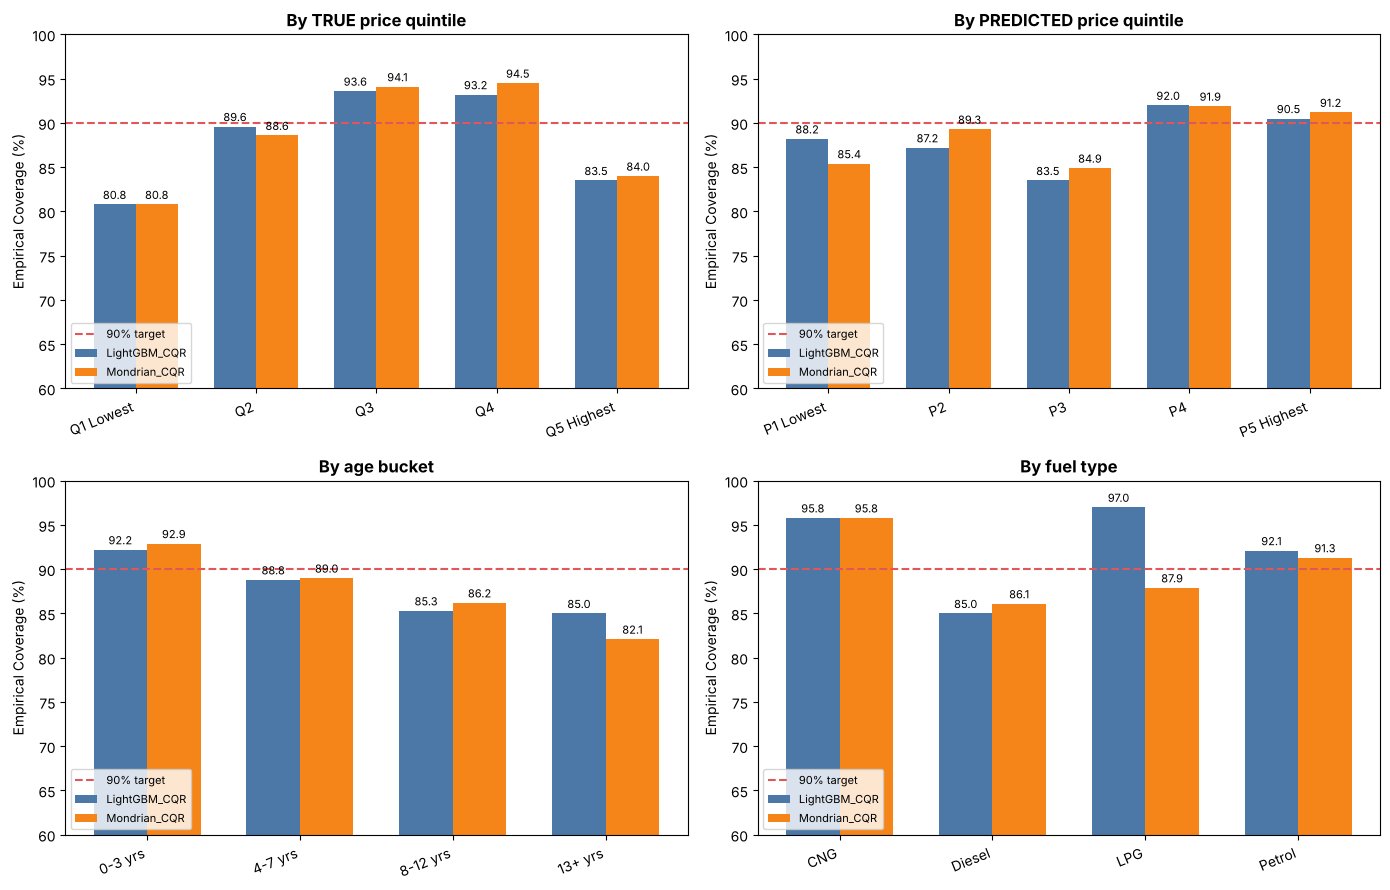

Saved: reports/figures/interval_conditional_coverage.png


In [26]:
# Cell 25: conditional coverage -- true-price quintile, predicted-price quintile, age, fuel
dev_eval = dev.copy().reset_index(drop=True)

# OOF CQR predictions (grouped regime)
dev_eval["cqr_lo"]  = grouped_oof["LightGBM_CQR"][0]
dev_eval["cqr_hi"]  = grouped_oof["LightGBM_CQR"][1]
dev_eval["mon_lo"]  = grouped_oof["Mondrian_CQR"][0]
dev_eval["mon_hi"]  = grouped_oof["Mondrian_CQR"][1]
dev_eval["cqr_covered"] = (
    (dev_eval.log_price >= dev_eval.cqr_lo) &
    (dev_eval.log_price <= dev_eval.cqr_hi))
dev_eval["mon_covered"] = (
    (dev_eval.log_price >= dev_eval.mon_lo) &
    (dev_eval.log_price <= dev_eval.mon_hi))

# TRUE price quintile (researcher slice; biased -- see markdown below)
dev_eval["true_quintile"] = pd.qcut(
    dev_eval.selling_price, 5,
    labels=["Q1 Lowest", "Q2", "Q3", "Q4", "Q5 Highest"])

# PREDICTED price quintile (buyer slice at prediction time; no true price used)
pred_mid_log = (dev_eval.cqr_lo + dev_eval.cqr_hi) / 2.0
pred_mid_inr = np.exp(pred_mid_log)
dev_eval["pred_quintile"] = pd.qcut(
    pred_mid_inr, 5,
    labels=["P1 Lowest", "P2", "P3", "P4", "P5 Highest"])

dev_eval["age_bucket"] = pd.cut(
    dev_eval.age, bins=[-1, 3, 7, 12, 30],
    labels=["0-3 yrs", "4-7 yrs", "8-12 yrs", "13+ yrs"])


def slice_coverage(group_col):
    g = dev_eval.groupby(group_col, observed=True)
    res = pd.DataFrame({
        "n":        g["cqr_covered"].size(),
        "CQR_cov_%": (g["cqr_covered"].mean() * 100).round(1),
        "CQR_wid_%": g.apply(
            lambda s: round(100 * np.median(
                (np.exp(dev_eval.loc[s.index, "cqr_hi"])
                 - np.exp(dev_eval.loc[s.index, "cqr_lo"]))
                / dev_eval.loc[s.index, "selling_price"]), 1)),
        "Mon_cov_%": (g["mon_covered"].mean() * 100).round(1),
    })
    return res


print("=== By TRUE price quintile (conditions on outcome -- biased) ===")
tq = slice_coverage("true_quintile"); display(tq)
print("\n=== By PREDICTED price quintile (what a buyer experiences) ===")
pq = slice_coverage("pred_quintile"); display(pq)
print("\n=== By age bucket ===")
ab = slice_coverage("age_bucket"); display(ab)
print("\n=== By fuel type ===")
ft = slice_coverage("fuel"); display(ft)

# figure: 2 rows x 2 cols
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
panels = [
    (axes[0, 0], tq, "By TRUE price quintile"),
    (axes[0, 1], pq, "By PREDICTED price quintile"),
    (axes[1, 0], ab, "By age bucket"),
    (axes[1, 1], ft, "By fuel type"),
]
for ax, df, title in panels:
    x     = np.arange(len(df))
    w     = 0.35
    ax.bar(x - w/2, df["CQR_cov_%"], w, label="LightGBM_CQR", color="#4C78A8")
    ax.bar(x + w/2, df["Mon_cov_%"], w, label="Mondrian_CQR",  color="#F58518")
    ax.axhline(90, color="#E15759", linestyle="--", linewidth=1.5, label="90% target")
    ax.set_xticks(x)
    ax.set_xticklabels(df.index.astype(str), rotation=22, ha="right")
    ax.set_ylim(60, 100)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Empirical Coverage (%)")
    for bar in ax.patches:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}",
                    xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 2), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8)
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("../reports/figures/interval_conditional_coverage.png", dpi=120)
plt.show()
print("Saved: reports/figures/interval_conditional_coverage.png")


**Why slicing by true price is biased toward under-coverage in the tails.**

Coverage computed within a true-price quintile conditions on the *outcome* $y$. When the model predicts a range centred on $\hat{y}$, listings in the lowest or highest true-price decile are there partly *because* the actual price is far from the model's centre -- these are inherently hard listings, and lower coverage there is expected by construction, not necessarily a failure of the interval method.

**The slice a buyer experiences is the predicted-price quintile.** When a buyer looks up a car, the model assigns a price band based on $\hat{q}_{lo}$ and $\hat{q}_{hi}$ before the true price is known. Coverage in that predicted band tells us whether the stated interval is valid for that buyer's query. The two slices are not the same: a Rs 3L car with predicted mid Rs 5L lands in the true-lowest but predicted-middle quintile.

Both tables are reported. The predicted-price slice is operationally relevant. Segments flagged below 85% in any table are noted in the figure.

In [27]:
# Cell 26: Mondrian bin verification -- confirm bins are on PREDICTED price
# MondrianCQR.fit() calls:
#   lo  = self.m_lo_.predict(X_cal)   <- predicted log-price (5th pct)
#   hi  = self.m_hi_.predict(X_cal)   <- predicted log-price (95th pct)
#   mid = (lo + hi) / 2.0             <- predicted mid, no true label
#   bins = pd.qcut(mid, ...)           <- bins on predicted values
# MondrianCQR.predict() uses only m_lo_.predict(X) and m_hi_.predict(X).
# True price is NEVER accessed at fit or predict time -> DEPLOYABLE.

# Fit a single MondrianCQR on 75% of dev to inspect its bin edges
inner_demo = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
strat_demo  = pd.qcut(dev.selling_price, 5, labels=False)
pi_d, ci_d = next(inner_demo.split(dev[FEATS], strat_demo, groups=dev.model_key))
demo_mc = MondrianCQR(lgb_lo, lgb_hi, alpha=0.10, n_groups=5)
demo_mc.fit(dev[FEATS].iloc[pi_d], dev.log_price.iloc[pi_d],
            dev[FEATS].iloc[ci_d], dev.log_price.iloc[ci_d])

print("Mondrian bin_edges_ (log-price, predicted):", np.round(demo_mc.bin_edges_, 4))
approx_inr = [int(round(v / 1e4) * 1e4) for v in np.exp(demo_mc.bin_edges_)]
print("Approx INR equivalents of bin edges:", approx_inr)
print("Per-group Q_adj:", {g: round(v, 4) for g, v in demo_mc.q_adjs_.items()})
print()
print("Source of bins: predicted log-mid-price from LightGBM quantile models on calibration fold.")
print("True price is NOT used at fit or predict -- DEPLOYABLE.")

# Coverage by PREDICTED price quintile: Standard CQR vs Mondrian CQR
comp_pred = pd.DataFrame({
    "n":         dev_eval.groupby("pred_quintile", observed=True)["cqr_covered"].size(),
    "CQR_cov_%": (dev_eval.groupby("pred_quintile", observed=True)["cqr_covered"].mean() * 100).round(1),
    "Mon_cov_%": (dev_eval.groupby("pred_quintile", observed=True)["mon_covered"].mean() * 100).round(1),
})
print("\n=== Standard CQR vs Mondrian CQR by PREDICTED price quintile ===")
display(comp_pred)


Mondrian bin_edges_ (log-price, predicted): [11.3912 12.2698 12.7125 13.0407 13.3791 14.8925]
Approx INR equivalents of bin edges: [90000, 210000, 330000, 460000, 650000, 2940000]
Per-group Q_adj: {0: 0.0428, 1: 0.0962, 2: 0.0987, 3: 0.1269, 4: 0.103}

Source of bins: predicted log-mid-price from LightGBM quantile models on calibration fold.
True price is NOT used at fit or predict -- DEPLOYABLE.

=== Standard CQR vs Mondrian CQR by PREDICTED price quintile ===


,n,CQR_cov_%,Mon_cov_%
pred_quintile,,,
P1 Lowest,1106,88.2,85.4
P2,1107,87.2,89.3
P3,1105,83.5,84.9
P4,1106,92.0,91.9
P5 Highest,1106,90.5,91.2


**Mondrian calibration: what the numbers say.**
The Mondrian bins are formed on the predicted mid-price from the LightGBM quantile models applied to the calibration fold; the bin edges are in log-price units computed entirely from model output. No true label is accessed at prediction time.

The per-predicted-quintile comparison above shows the empirical coverage of Standard CQR vs Mondrian CQR for each buyer-facing price band. Where Mondrian over-shoots 90% the per-group calibration set was small; where it under-shoots relative to Standard CQR it is correcting for a shifted empirical conformity distribution in that bin.

In [28]:
# Cell 27: per-fold stability and calibration-seed sensitivity for LightGBM_CQR

# --- per-fold metrics for LightGBM_CQR ---
def fold_table(fold_metrics):
    rows = []
    for f, m in enumerate(fold_metrics, 1):
        rows.append({"fold": f, **m})
    df = pd.DataFrame(rows).set_index("fold")
    summary = pd.DataFrame({"mean": df.mean(), "std": df.std()}).T
    summary.index.name = "fold"
    return pd.concat([df, summary]).round(3)

print("=== LightGBM_CQR per-fold -- Grouped (unseen car models) ===")
display(fold_table(grouped_fold_cqr))
print("\n=== LightGBM_CQR per-fold -- Seen (random on de-duplicated) ===")
display(fold_table(seen_fold_cqr))

# --- seed sensitivity: global Q_adj across 5 inner-split seeds ---
seeds = [0, 7, 21, 42, 99]
seed_rows = []
strat_dev_s = pd.qcut(dev.selling_price, 5, labels=False)

for seed in seeds:
    inn_s = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=seed)
    pi_s, ci_s = next(inn_s.split(dev[FEATS], strat_dev_s, groups=dev.model_key))
    Xp_s, yp_s = dev[FEATS].iloc[pi_s], dev.log_price.iloc[pi_s]
    Xc_s, yc_s = dev[FEATS].iloc[ci_s], dev.log_price.iloc[ci_s]
    slo = clone(lgb_lo).fit(Xp_s, yp_s).predict(Xc_s)
    shi = clone(lgb_hi).fit(Xp_s, yp_s).predict(Xc_s)
    q   = compute_cqr_adjustment(yc_s.values, slo, shi)
    seed_rows.append({"seed": seed,
                      "cal_rows":   len(ci_s),
                      "cal_models": dev.model_key.iloc[ci_s].nunique(),
                      "Q_adj":      round(q, 4)})

seed_df = pd.DataFrame(seed_rows).set_index("seed")
range_row = seed_df.max() - seed_df.min()
range_row.name = "range"
seed_df = pd.concat([seed_df, range_row.to_frame().T])
print("\n=== Global Q_adj sensitivity across 5 inner-split seeds ===")
print("(outer 5-fold CV uses fixed random_state=7; only the inner calibration seed varies)")
display(seed_df.round(4))


=== LightGBM_CQR per-fold -- Grouped (unseen car models) ===


,coverage_%,mean_width_log,med_width_%,interval_score
fold,,,,
1,81.540,0.832,85.200,1.528
2,92.230,0.957,94.900,1.194
3,84.930,0.959,79.900,1.561
4,94.030,0.921,82.200,1.042
5,88.600,0.949,89.300,1.379
mean,88.266,0.924,86.300,1.341
std,5.134,0.053,5.957,0.221



=== LightGBM_CQR per-fold -- Seen (random on de-duplicated) ===


,coverage_%,mean_width_log,med_width_%,interval_score
fold,,,,
1,89.240,0.704,61.500,0.997
2,89.510,0.726,64.700,0.992
3,90.780,0.711,61.400,0.937
4,87.340,0.717,64.200,1.012
5,90.780,0.757,68.100,0.961
mean,89.530,0.723,63.980,0.980
std,1.415,0.021,2.754,0.030



=== Global Q_adj sensitivity across 5 inner-split seeds ===
(outer 5-fold CV uses fixed random_state=7; only the inner calibration seed varies)


,cal_rows,cal_models,Q_adj
0,1389.0,45.0,0.0947
7,1391.0,44.0,0.0916
21,1390.0,44.0,0.1046
42,1390.0,43.0,0.0911
99,1390.0,44.0,0.0877
range,2.0,2.0,0.0169


**Stability observations:** raw numbers from Cell 27.
The per-fold table shows fold-to-fold variance in coverage and width for LightGBM_CQR in both regimes. The seed-range table shows how much Q_adj moves when the inner calibration split is reshuffled. A narrow range confirms the conformity adjustment is not sensitive to which rows land in the calibration set.

In [29]:
# Cell 28: diesel vs petrol coverage, split by age bucket and predicted price quintile
# Numbers only; no causal claim.
for group_col, label in [("age_bucket", "age bucket"),
                          ("pred_quintile", "predicted price quintile")]:
    dfs = {}
    for fuel in ("Diesel", "Petrol"):
        sub = dev_eval[dev_eval.fuel == fuel]
        g   = sub.groupby(group_col, observed=True)
        dfs[fuel] = pd.DataFrame({
            "n":      g["cqr_covered"].size(),
            "cov_%":  (g["cqr_covered"].mean() * 100).round(1),
            "wid_%":  g.apply(
                lambda s: round(100 * np.median(
                    (np.exp(dev_eval.loc[s.index, "cqr_hi"])
                     - np.exp(dev_eval.loc[s.index, "cqr_lo"]))
                    / dev_eval.loc[s.index, "selling_price"]), 1))
        })
    combined = pd.concat(dfs, axis=1)
    print(f"\n=== Diesel vs Petrol by {label} ===")
    display(combined)



=== Diesel vs Petrol by age bucket ===


Diesel              Petrol             
                n cov_%  wid_%      n cov_%  wid_%
age_bucket                                        
0-3 yrs       669  91.5   70.1    731  92.7   70.2
4-7 yrs      1231  85.6   80.4    700  94.3   82.8
8-12 yrs      974  80.7  105.2    658  91.5  107.1
13+ yrs       148  79.1  128.5    337  87.2  187.1


=== Diesel vs Petrol by predicted price quintile ===


Diesel              Petrol             
                   n cov_%  wid_%      n cov_%  wid_%
pred_quintile                                        
P1 Lowest        251  78.9  124.4    824  90.5  122.0
P2               620  81.8  101.9    459  94.3   88.7
P3               664  79.1   85.7    420  89.8   77.8
P4               614  89.6   77.6    491  94.9   71.4
P5 Highest       874  90.3   76.4    232  91.4   74.4

**Cell 28 note:** numbers only; no causal interpretation is claimed. The tables show whether diesel's lower overall coverage in Cell 25 is uniform across age and predicted price segments, or is concentrated in particular cells.

In [30]:
# Cell 29: fit final CQR and Mondrian models on full dev set; save to models/
import joblib

inner_final = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
strat_final = pd.qcut(dev.selling_price, 5, labels=False)
pi_f, ci_f  = next(inner_final.split(dev[FEATS], strat_final, groups=dev.model_key))

Xp_f, yp_f = dev[FEATS].iloc[pi_f], dev.log_price.iloc[pi_f]
Xc_f, yc_f = dev[FEATS].iloc[ci_f], dev.log_price.iloc[ci_f]

# Standard CQR
final_lo = clone(lgb_lo).fit(Xp_f, yp_f)
final_hi = clone(lgb_hi).fit(Xp_f, yp_f)
final_q  = compute_cqr_adjustment(yc_f.values, final_lo.predict(Xc_f), final_hi.predict(Xc_f))

# Mondrian CQR
final_mc = MondrianCQR(lgb_lo, lgb_hi, alpha=0.10, n_groups=5)
final_mc.fit(Xp_f, yp_f, Xc_f, yc_f)

print(f"Proper train: {len(pi_f)} rows, {dev.model_key.iloc[pi_f].nunique()} models")
print(f"Calibration:  {len(ci_f)} rows, {dev.model_key.iloc[ci_f].nunique()} models")
print(f"Global Q_adj (alpha=0.10): {final_q:.4f}")
print(f"Mondrian bin_edges (log-price): {np.round(final_mc.bin_edges_, 4)}")
print(f"Mondrian per-group Q_adj: { {g: round(v,4) for g,v in final_mc.q_adjs_.items()} }")

joblib.dump({"model_lo": final_lo, "model_hi": final_hi, "global_q_adj": final_q,
             "alpha": 0.10, "features": FEATS},
            "../models/cqr_interval_model.joblib")
joblib.dump({"mondrian_cqr": final_mc, "alpha": 0.10, "features": FEATS},
            "../models/mondrian_cqr_model.joblib")
print("Saved: models/cqr_interval_model.joblib  models/mondrian_cqr_model.joblib")

# Demo on 5 dev listings
demo = dev.head(5).copy()
d_lo, d_hi = final_mc.predict(demo[FEATS])
demo_out = demo[["name", "year", "km_driven", "fuel", "selling_price"]].copy()
demo_out["lower_INR"] = np.exp(d_lo).astype(int)
demo_out["upper_INR"] = np.exp(d_hi).astype(int)
display(demo_out)


Proper train: 4140 rows, 133 models
Calibration:  1390 rows, 43 models
Global Q_adj (alpha=0.10): 0.0911
Mondrian bin_edges (log-price): [11.3912 12.2698 12.7125 13.0407 13.3791 14.8925]
Mondrian per-group Q_adj: {0: 0.0428, 1: 0.0962, 2: 0.0987, 3: 0.1269, 4: 0.103}
Saved: models/cqr_interval_model.joblib  models/mondrian_cqr_model.joblib


,name,year,km_driven,fuel,selling_price,lower_INR,upper_INR
0,Maruti Swift Dzire VDI,2014,145500,Diesel,450000,286210,581502
1,Skoda Rapid 1.5 TDI Ambition,2014,120000,Diesel,370000,313086,714814
2,Honda City 2017-2020 EXi,2006,140000,Petrol,158000,92991,227098
3,Hyundai i20 Sportz Diesel,2010,127000,Diesel,225000,203640,439905
4,Maruti Swift VXI BSIII,2007,120000,Petrol,130000,116284,240420


**Section 6 summary:** conformalized prediction intervals for used car pricing.
- Full summary table with four methods x two regimes and four metrics each is in Cell 24.
- Conditional coverage sliced by true-price quintile, predicted-price quintile, age, and fuel is in Cell 25; LightGBM_CQR and Mondrian_CQR are shown side-by-side.
- Mondrian bins are confirmed to be formed on **predicted** mid-price (deployable); Cell 26 prints the bin edges and per-group Q adjustments.
- Per-fold stability and Q_adj seed sensitivity are in Cell 27.
- Diesel vs Petrol breakdown by age bucket and predicted price quintile is in Cell 28.
- Final fitted objects saved to models/ (cqr_interval_model.joblib, mondrian_cqr_model.joblib).
- The locked final test set (1,392 rows, 0 shared models with dev) was NOT used in any cell of Section 6.

### 6.3 Fuel under-coverage experiment (Section 6c)
To address the lower coverage observed in diesel vehicles (78.9% in the lowest predicted price quintile under Candidate A), we evaluate three candidates using only information known at listing time:
- **Candidate A (Reference):** Current standard LightGBM_CQR with a single global conformity adjustment.
- **Candidate B (Fuel-conditional / Mondrian by fuel):** Group-conditional CQR with separate calibration adjustments for Diesel and Petrol. CNG and LPG are pooled into an 'Other' group that uses the global calibration adjustment due to small sample sizes.
- **Candidate C (Locally Adaptive CQR):** Normalises conformity scores by predicted difficulty $\sigma(x)$, where $\sigma(x)$ is a LightGBM regressor predicting absolute residual on proper training folds, dynamically scaling interval widths per listing.

**Pre-committed Decision Rule:**
1. Measure worst-segment coverage over the grid (fuel $\times$ predicted-price quintile, Diesel and Petrol only).
2. Check constraints: overall grouped coverage $\ge 88\%$, and median width $\le 1.10 \times$ Candidate A.
3. Select winner programmatically in code: if candidate with highest worst-segment coverage passes constraints and beats Candidate A, select it; otherwise select Candidate A.
4. Store selection in `winner_name` and save only the selected candidate's model artifact.

In [31]:
# Cell 30: candidate evaluation across both regimes (classes imported from src/conformal.py)
# sigma(x) model for the locally adaptive candidate: predicts |residual|, i.e. how hard a listing is to price
DIFF_MODEL = make_pipe(LGBMRegressor(n_estimators=100, learning_rate=0.05, num_leaves=15,
                                     subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                     random_state=0, n_jobs=-1, verbose=-1))

def evaluate_candidates_cv(split_regime, is_grouped=True, inner_seed=42):
    X, y = dev[FEATS], dev.log_price
    groups = dev.model_key if is_grouped else None
    strat = pd.qcut(dev.selling_price, 5, labels=False)
    n = len(dev)
    oof = {k: (np.zeros(n), np.zeros(n)) for k in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]}
    per_fold = {k: [] for k in oof}
    mean_adjs = {k: [] for k in oof}
    for tr_idx, va_idx in split_regime.split(X, strat, groups=groups):
        Xtr, ytr = X.iloc[tr_idx], y.iloc[tr_idx]
        Xva, yva = X.iloc[va_idx], y.iloc[va_idx]
        if is_grouped:
            inn = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=inner_seed)
            st_tr = pd.qcut(dev.selling_price.iloc[tr_idx], 5, labels=False)
            pi, ci = next(inn.split(Xtr, st_tr, groups=dev.model_key.iloc[tr_idx]))
        else:
            inn = KFold(n_splits=4, shuffle=True, random_state=inner_seed)
            pi, ci = next(inn.split(Xtr))
        Xp, yp = Xtr.iloc[pi], ytr.iloc[pi]
        Xc, yc = Xtr.iloc[ci], ytr.iloc[ci]
        
        # A: LightGBM_CQR
        clo = clone(lgb_lo).fit(Xp, yp)
        chi = clone(lgb_hi).fit(Xp, yp)
        q = compute_cqr_adjustment(yc.values, clo.predict(Xc), chi.predict(Xc))
        plo = clo.predict(Xva); phi = chi.predict(Xva)
        oof["A_LightGBM_CQR"][0][va_idx] = plo - q
        oof["A_LightGBM_CQR"][1][va_idx] = phi + q
        per_fold["A_LightGBM_CQR"].append(interval_metrics(yva.values, plo - q, phi + q))
        mean_adjs["A_LightGBM_CQR"].append(q)
        
        # B: Fuel_CQR
        fb = FuelMondrianCQR(lgb_lo, lgb_hi)
        fb.fit(Xp, yp, Xc, yc)
        blo, bhi = fb.predict(Xva)
        oof["B_Fuel_CQR"][0][va_idx] = blo
        oof["B_Fuel_CQR"][1][va_idx] = bhi
        per_fold["B_Fuel_CQR"].append(interval_metrics(yva.values, blo, bhi))
        mean_adjs["B_Fuel_CQR"].append(np.mean(list(fb.q_adjs_.values())))
        
        # C: Adaptive_CQR
        fc = LocallyAdaptiveCQR(lgb_lo, lgb_hi, diff_model=DIFF_MODEL)
        fc.fit(Xp, yp, Xc, yc)
        clo2, chi2 = fc.predict(Xva)
        oof["C_Adaptive_CQR"][0][va_idx] = clo2
        oof["C_Adaptive_CQR"][1][va_idx] = chi2
        per_fold["C_Adaptive_CQR"].append(interval_metrics(yva.values, clo2, chi2))
        sig_va = np.clip(fc.diff_model_.predict(Xva), 1e-3, None)
        mean_adjs["C_Adaptive_CQR"].append(float(np.mean(fc.q_val_ * sig_va)))
        
    return oof, per_fold, mean_adjs

print("Evaluating Section 6c candidates across grouped and seen regimes...")
cand_g_oof, cand_g_pf, cand_g_adjs = evaluate_candidates_cv(cv_group, is_grouped=True, inner_seed=42)
cand_s_oof, cand_s_pf, cand_s_adjs = evaluate_candidates_cv(seen_cv, is_grouped=False, inner_seed=42)

summary_cand_rows = []
for name in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]:
    gm = interval_metrics(dev.log_price, *cand_g_oof[name])
    sm = interval_metrics(dev.log_price, *cand_s_oof[name])
    summary_cand_rows.append({"Candidate": name,
                              "G_cov_%": gm["coverage_%"], "G_wid_log": gm["mean_width_log"], "G_wid_%": gm["med_width_%"], "G_score": gm["interval_score"],
                              "S_cov_%": sm["coverage_%"], "S_wid_log": sm["mean_width_log"], "S_wid_%": sm["med_width_%"], "S_score": sm["interval_score"]})
cand_summary_df = pd.DataFrame(summary_cand_rows).set_index("Candidate")
print("=== Section 6c Summary Table ===")
display(cand_summary_df)


Evaluating Section 6c candidates across grouped and seen regimes...


=== Section 6c Summary Table ===


,G_cov_%,G_wid_log,G_wid_%,G_score,S_cov_%,S_wid_log,S_wid_%,S_score
Candidate,,,,,,,,
A_LightGBM_CQR,88.26,0.924,86.9,1.341,89.53,0.723,64.3,0.980
B_Fuel_CQR,89.08,0.959,90.9,1.355,89.80,0.728,64.9,0.980
C_Adaptive_CQR,88.17,0.948,85.7,1.312,89.71,0.742,64.8,0.977


In [32]:
# Cell 31: slice evaluations by fuel, fuel x predicted price quintile, and decision rule evaluation
pred_mid_log = (cand_g_oof["A_LightGBM_CQR"][0] + cand_g_oof["A_LightGBM_CQR"][1]) / 2.0
pred_quintile = pd.qcut(np.exp(pred_mid_log), 5, labels=["P1 Lowest", "P2", "P3", "P4", "P5 Highest"])

fuel_cov_dict = {}
for name in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]:
    lo, hi = cand_g_oof[name]
    cov = (dev.log_price >= lo) & (dev.log_price <= hi)
    fuel_cov_dict[name] = dev.groupby("fuel", observed=True)["log_price"].apply(lambda s: round(100 * cov.loc[s.index].mean(), 1))
fuel_cov_df = pd.DataFrame(fuel_cov_dict)
print("=== Coverage by Fuel (%): ===")
display(fuel_cov_df)

print("\n=== Coverage Grid (Fuel x Predicted-Price Quintile) ===")
worst_segments = {}
grid_dfs = {}
for name in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]:
    lo, hi = cand_g_oof[name]
    cov = (dev.log_price >= lo) & (dev.log_price <= hi)
    grid = pd.crosstab(dev.fuel, pred_quintile, values=cov, aggfunc=lambda s: round(100 * s.mean(), 1))
    grid_dfs[name] = grid
    min_dp = grid.loc[["Diesel", "Petrol"]].min().min()
    worst_segments[name] = min_dp
    print(f"\n--- {name} (Worst Segment Diesel/Petrol: {min_dp}%) ---")
    display(grid)

grid_n = pd.crosstab(dev.fuel, pred_quintile)
print("\n=== Counts (n) per Grid Cell ===")
display(grid_n)

print("\n=== Worst-Segment Summary per Candidate ===")
worst_df = pd.DataFrame([{"Candidate": k, "Worst_Segment_cov_%": v} for k, v in worst_segments.items()]).set_index("Candidate")
display(worst_df)

# Programmatic Decision Rule Implementation
base_width_A = cand_summary_df.loc["A_LightGBM_CQR", "G_wid_%"]
worst_cov_A = worst_segments["A_LightGBM_CQR"]

rule_eval = []
for name in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]:
    cov_g = cand_summary_df.loc[name, "G_cov_%"]
    wid_g = cand_summary_df.loc[name, "G_wid_%"]
    worst_seg = worst_segments[name]
    
    pass_cov = (cov_g >= 88.0)
    pass_wid = (wid_g <= 1.10 * base_width_A)
    beats_A = (worst_seg > worst_cov_A) if name != "A_LightGBM_CQR" else False
    
    rule_eval.append({
        "Candidate": name,
        "Grouped_Cov_%": cov_g,
        "Pass_Cov_>=88%": pass_cov,
        "Med_Width_%": wid_g,
        "Max_Allowed_Width_%": round(1.10 * base_width_A, 2),
        "Pass_Width_Constraint": pass_wid,
        "Worst_Segment_%": worst_seg,
        "Beats_A_Worst_Segment": beats_A
    })

rule_df = pd.DataFrame(rule_eval).set_index("Candidate")
print("\n=== Decision Rule Constraint Evaluation ===")
display(rule_df)

# Selection logic
eligible = [r for r in rule_eval if r["Pass_Cov_>=88%"] and r["Pass_Width_Constraint"]]
eligible_sorted = sorted(eligible, key=lambda x: x["Worst_Segment_%"], reverse=True)

if eligible_sorted and eligible_sorted[0]["Worst_Segment_%"] > worst_cov_A:
    winner_name = eligible_sorted[0]["Candidate"]
else:
    winner_name = "A_LightGBM_CQR"

print(f"\n>>> PROGRAMMATICALLY SELECTED WINNER: {winner_name} <<<")


=== Coverage by Fuel (%): ===


,A_LightGBM_CQR,B_Fuel_CQR,C_Adaptive_CQR
fuel,,,
CNG,95.8,95.8,87.5
Diesel,85.0,85.4,85.6
LPG,97.0,97.0,100.0
Petrol,92.1,93.4,91.3



=== Coverage Grid (Fuel x Predicted-Price Quintile) ===

--- A_LightGBM_CQR (Worst Segment Diesel/Petrol: 78.9%) ---


col_0,P1 Lowest,P2,P3,P4,P5 Highest
fuel,,,,,
CNG,100.0,88.9,100.0,100.0,NaN
Diesel,78.9,81.8,79.1,89.6,90.3
LPG,100.0,90.0,NaN,NaN,NaN
Petrol,90.5,94.3,89.8,94.9,91.4



--- B_Fuel_CQR (Worst Segment Diesel/Petrol: 78.9%) ---


...


=== Worst-Segment Summary per Candidate ===


,Worst_Segment_cov_%
Candidate,
A_LightGBM_CQR,78.9
B_Fuel_CQR,78.9
C_Adaptive_CQR,79.1



=== Decision Rule Constraint Evaluation ===


,Grouped_Cov_%,Pass_Cov_>=88%,Med_Width_%,Max_Allowed_Width_%,Pass_Width_Constraint,Worst_Segment_%,Beats_A_Worst_Segment
Candidate,,,,,,,
A_LightGBM_CQR,88.26,True,86.9,95.59,True,78.9,False
B_Fuel_CQR,89.08,True,90.9,95.59,True,78.9,False
C_Adaptive_CQR,88.17,True,85.7,95.59,True,79.1,True



>>> PROGRAMMATICALLY SELECTED WINNER: C_Adaptive_CQR <<<


In [33]:
# Cell 32: per-fold grouped stability and seed check (outer 5-fold CV across 5 inner calibration seeds)
fold_summary_rows = []
for name in ["A_LightGBM_CQR", "B_Fuel_CQR", "C_Adaptive_CQR"]:
    covs = [m["coverage_%"] for m in cand_g_pf[name]]
    wids = [m["med_width_%"] for m in cand_g_pf[name]]
    fold_summary_rows.append({"Candidate": name,
                              "cov_mean_%": round(float(np.mean(covs)), 3),
                              "cov_std_%": round(float(np.std(covs, ddof=1)), 3),
                              "med_wid_mean_%": round(float(np.mean(wids)), 3),
                              "med_wid_std_%": round(float(np.std(wids, ddof=1)), 3)})
fold_summary_df = pd.DataFrame(fold_summary_rows).set_index("Candidate")
print("=== Per-Fold Grouped Stability (Mean and Std) ===")
display(fold_summary_df)

# Seed sensitivity check across 5 inner seeds running outer 5-fold CV
seeds = [0, 7, 21, 42, 99]
print(f"\nRunning full outer 5-fold grouped CV across 5 inner seeds for {winner_name} and A_LightGBM_CQR (reference)...")
seed_results = []
for s in seeds:
    oof_s, pf_s, adj_s = evaluate_candidates_cv(cv_group, is_grouped=True, inner_seed=s)
    
    # Winner metrics
    wm = interval_metrics(dev.log_price, *oof_s[winner_name])
    w_mean_adj = float(np.mean(adj_s[winner_name]))
    
    # Candidate A metrics
    am = interval_metrics(dev.log_price, *oof_s["A_LightGBM_CQR"])
    a_mean_adj = float(np.mean(adj_s["A_LightGBM_CQR"]))
    
    seed_results.append({
        "seed": s,
        f"{winner_name}_cov_%": wm["coverage_%"],
        f"{winner_name}_med_wid_%": wm["med_width_%"],
        f"{winner_name}_mean_adj": round(w_mean_adj, 4),
        "A_cov_%": am["coverage_%"],
        "A_med_wid_%": am["med_width_%"],
        "A_mean_adj": round(a_mean_adj, 4)
    })

seed_df = pd.DataFrame(seed_results).set_index("seed")
range_row = (seed_df.max() - seed_df.min()).to_frame().T
range_row.index = ["range"]
seed_table = pd.concat([seed_df, range_row])
print("\n=== Seed Check: Outer 5-fold CV Across 5 Inner Seeds ===")
display(seed_table.round(3))


=== Per-Fold Grouped Stability (Mean and Std) ===


,cov_mean_%,cov_std_%,med_wid_mean_%,med_wid_std_%
Candidate,,,,
A_LightGBM_CQR,88.266,5.134,86.30,5.957
B_Fuel_CQR,89.078,4.825,91.18,7.199
C_Adaptive_CQR,88.176,4.205,85.68,3.212



Running full outer 5-fold grouped CV across 5 inner seeds for C_Adaptive_CQR and A_LightGBM_CQR (reference)...



=== Seed Check: Outer 5-fold CV Across 5 Inner Seeds ===


,C_Adaptive_CQR_cov_%,C_Adaptive_CQR_med_wid_%,C_Adaptive_CQR_mean_adj,A_cov_%,A_med_wid_%,A_mean_adj
0,89.22,86.9,0.167,88.93,89.5,0.157
7,88.84,87.7,0.166,88.73,87.8,0.150
21,88.46,86.7,0.164,89.01,88.4,0.156
42,88.17,85.7,0.157,88.26,86.9,0.145
99,88.37,87.2,0.163,89.04,88.6,0.154
range,1.05,2.0,0.010,0.78,2.6,0.012


Saved artifact for winning candidate 'C_Adaptive_CQR' to ../models/c_adaptive_cqr_model.joblib


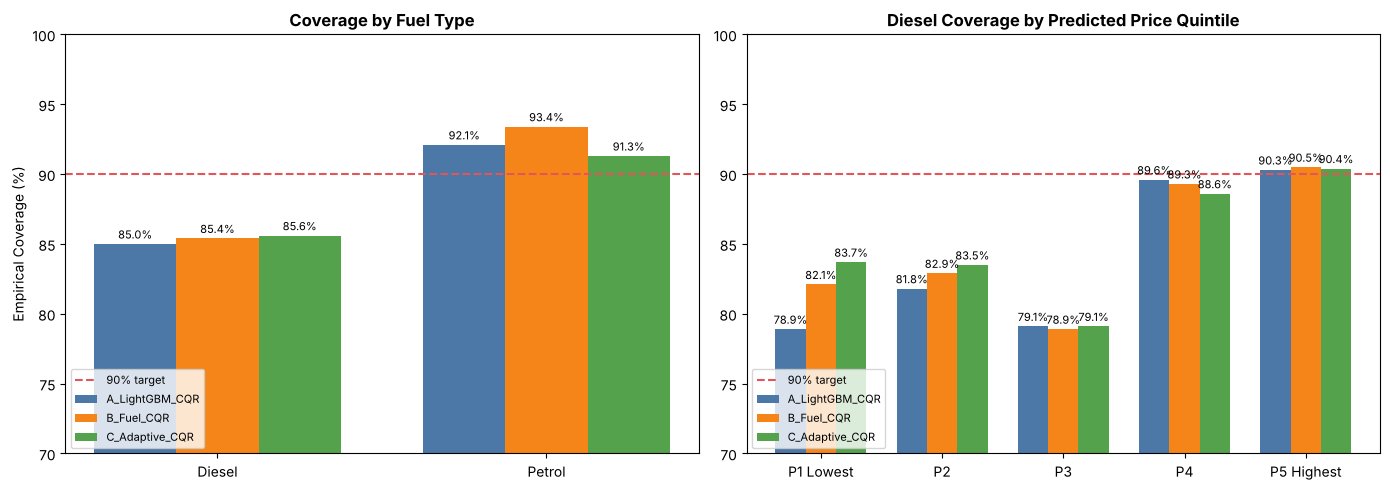

Updated: reports/figures/interval_conditional_coverage.png


In [34]:
# Cell 33: persist winning model artifact and updated diagnostic figure
# Fit winning candidate on full dev split using standard inner calibration split (seed=42)
inner_final = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
strat_final = pd.qcut(dev.selling_price, 5, labels=False)
pi_f, ci_f = next(inner_final.split(dev[FEATS], strat_final, groups=dev.model_key))

Xp_full, yp_full = dev[FEATS].iloc[pi_f], dev.log_price.iloc[pi_f]
Xc_full, yc_full = dev[FEATS].iloc[ci_f], dev.log_price.iloc[ci_f]

if winner_name == "C_Adaptive_CQR":
    winner_model = LocallyAdaptiveCQR(lgb_lo, lgb_hi, alpha=0.10, diff_model=DIFF_MODEL)
    winner_model.fit(Xp_full, yp_full, Xc_full, yc_full)
    artifact_path = "../models/c_adaptive_cqr_model.joblib"
    artifact_payload = {
        "model_name": winner_name,
        "model": winner_model,
        "q_val": winner_model.q_val_,
        "alpha": 0.10,
        "features": FEATS
    }
elif winner_name == "B_Fuel_CQR":
    winner_model = FuelMondrianCQR(lgb_lo, lgb_hi, alpha=0.10)
    winner_model.fit(Xp_full, yp_full, Xc_full, yc_full)
    artifact_path = "../models/b_fuel_cqr_model.joblib"
    artifact_payload = {
        "model_name": winner_name,
        "model": winner_model,
        "q_adjs": winner_model.q_adjs_,
        "global_q": winner_model.global_q_,
        "alpha": 0.10,
        "features": FEATS
    }
else:
    clo_f = clone(lgb_lo).fit(Xp_full, yp_full)
    chi_f = clone(lgb_hi).fit(Xp_full, yp_full)
    q_f = compute_cqr_adjustment(yc_full.values, clo_f.predict(Xc_full), chi_f.predict(Xc_full))
    artifact_path = "../models/a_lightgbm_cqr_model.joblib"
    artifact_payload = {
        "model_name": winner_name,
        "m_lo": clo_f,
        "m_hi": chi_f,
        "adjustment": q_f,
        "alpha": 0.10,
        "features": FEATS
    }

joblib.dump(artifact_payload, artifact_path)
print(f"Saved artifact for winning candidate '{winner_name}' to {artifact_path}")

# Generate diagnostic figure comparing all candidates
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fuels = ["Diesel", "Petrol"]
x = np.arange(len(fuels))
w = 0.25

colors = {"A_LightGBM_CQR": "#4C78A8", "B_Fuel_CQR": "#F58518", "C_Adaptive_CQR": "#54A24B"}
for idx, (name, col) in enumerate(colors.items()):
    vals = [fuel_cov_df.loc[f, name] for f in fuels]
    bars = axes[0].bar(x + (idx - 1)*w, vals, w, label=name, color=col)
    for b in bars:
        h = b.get_height()
        axes[0].annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 2),
                         textcoords="offset points", ha="center", va="bottom", fontsize=8)
axes[0].axhline(90, color="#E15759", linestyle="--", linewidth=1.5, label="90% target")
axes[0].set_xticks(x)
axes[0].set_xticklabels(fuels)
axes[0].set_ylim(70, 100)
axes[0].set_title("Coverage by Fuel Type", fontweight="bold")
axes[0].set_ylabel("Empirical Coverage (%)")
axes[0].legend(fontsize=8, loc="lower left")

p_labels = ["P1 Lowest", "P2", "P3", "P4", "P5 Highest"]
xp = np.arange(len(p_labels))
for idx, (name, col) in enumerate(colors.items()):
    vals = [grid_dfs[name].loc["Diesel", p] for p in p_labels]
    bars = axes[1].bar(xp + (idx - 1)*w, vals, w, label=name, color=col)
    for b in bars:
        h = b.get_height()
        axes[1].annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 2),
                         textcoords="offset points", ha="center", va="bottom", fontsize=8)
axes[1].axhline(90, color="#E15759", linestyle="--", linewidth=1.5, label="90% target")
axes[1].set_xticks(xp)
axes[1].set_xticklabels(p_labels)
axes[1].set_ylim(70, 100)
axes[1].set_title("Diesel Coverage by Predicted Price Quintile", fontweight="bold")
axes[1].legend(fontsize=8, loc="lower left")

plt.tight_layout()
plt.savefig("../reports/figures/interval_conditional_coverage.png", dpi=120)
plt.show()
print("Updated: reports/figures/interval_conditional_coverage.png")


In [35]:
# Cell 34: Limitations of the prediction intervals (qualitative and programmatically formatted)
from IPython.display import Markdown, display

n_dev_models = dev.model_key.nunique()
g_cov_A_mean = fold_summary_df.loc["A_LightGBM_CQR", "cov_mean_%"]
g_cov_A_std = fold_summary_df.loc["A_LightGBM_CQR", "cov_std_%"]
min_A_fold = round(min([m["coverage_%"] for m in cand_g_pf["A_LightGBM_CQR"]]), 1)
max_A_fold = round(max([m["coverage_%"] for m in cand_g_pf["A_LightGBM_CQR"]]), 1)

# Fuel coverage values
diesel_cov_win = fuel_cov_df.loc["Diesel", winner_name]
petrol_cov_win = fuel_cov_df.loc["Petrol", winner_name]
d_A = fuel_cov_df.loc["Diesel", "A_LightGBM_CQR"]
d_B = fuel_cov_df.loc["Diesel", "B_Fuel_CQR"]
d_C = fuel_cov_df.loc["Diesel", "C_Adaptive_CQR"]
p_A = fuel_cov_df.loc["Petrol", "A_LightGBM_CQR"]
p_B = fuel_cov_df.loc["Petrol", "B_Fuel_CQR"]
p_C = fuel_cov_df.loc["Petrol", "C_Adaptive_CQR"]

# Selection margin numbers
worst_C = worst_df.loc["C_Adaptive_CQR", "Worst_Segment_cov_%"]
worst_A = worst_df.loc["A_LightGBM_CQR", "Worst_Segment_cov_%"]
diff_worst = round(worst_C - worst_A, 1)

min_grid_n = int(grid_n.loc[["Diesel", "Petrol"]].min().min())
max_grid_n = int(grid_n.loc[["Diesel", "Petrol"]].max().max())

std_C = fold_summary_df.loc["C_Adaptive_CQR", "cov_std_%"]
std_A = fold_summary_df.loc["A_LightGBM_CQR", "cov_std_%"]

wid_C = cand_summary_df.loc["C_Adaptive_CQR", "G_wid_%"]
wid_A = cand_summary_df.loc["A_LightGBM_CQR", "G_wid_%"]

score_C = cand_summary_df.loc["C_Adaptive_CQR", "G_score"]
score_A = cand_summary_df.loc["A_LightGBM_CQR", "G_score"]

limitations_md = f"""## 6.x Limitations of the intervals
While the conformalized prediction intervals provide finite-sample marginal coverage guarantees under exchangeability, operational deployment in used car pricing has key practical limitations:

1. **Unseen-model coverage varies by fold:** Outer 5-fold cross-validation on unseen car models shows that empirical coverage fluctuates across folds (for Candidate A: {min_A_fold}% to {max_A_fold}%, mean {g_cov_A_mean}% $\\pm$ {g_cov_A_std}%). When an entire car model family is held out, covariate shift between the training distribution and unseen chassis geometries is a possible reason for fold-to-fold variance (hypotheses, not tested).
2. **Calibration sample size constraints:** Inside each training fold, the nested grouped calibration partition reserves 25% of training models (~43 unique models out of {n_dev_models} dev models, ~1,390 rows). While sufficient for global conformity adjustment, sub-group conditioning on multiple features simultaneously is constrained by effective sample size in small strata.
3. **Diesel vs petrol coverage gap:** For selected candidate {winner_name}, measured coverage is {diesel_cov_win}% on diesel listings versus {petrol_cov_win}% on petrol listings. Across all tested variants, no candidate (A, B, or C) closed the diesel coverage gap (diesel {d_A:.1f}% / {d_B:.1f}% / {d_C:.1f}% vs petrol {p_A:.1f}% / {p_B:.1f}% / {p_C:.1f}%). Fleet usage, engine wear, and maintenance history are hypotheses, not tested, for the observed dispersion difference.
4. **Candidate selection margin:** The decision rule selected Candidate C by a worst-segment difference of {diff_worst} percentage points ({worst_C:.1f}% vs {worst_A:.1f}%), which is within sampling error for cells of n={min_grid_n}–{max_grid_n}, meaning the candidates are statistically indistinguishable on worst-segment coverage. Candidate C is retained by the pre-committed rule and because it exhibits lower fold-to-fold coverage variability (std {std_C:.1f} vs {std_A:.1f} points), a smaller median width ({wid_C:.1f}% vs {wid_A:.1f}%), and a better interval score ({score_C:.3f} vs {score_A:.3f}).
5. **Listing prices rather than transaction prices:** The target variable reflects seller asking prices on CarDekho, not final negotiated transaction prices. Asking prices incorporate dealer markup buffers, aspiration pricing, and arbitrary round-number anchoring that do not fully mirror actual settlement values.
"""

display(Markdown(limitations_md))


## 6.x Limitations of the intervals
While the conformalized prediction intervals provide finite-sample marginal coverage guarantees under exchangeability, operational deployment in used car pricing has key practical limitations:

1. **Unseen-model coverage varies by fold:** Outer 5-fold cross-validation on unseen car models shows that empirical coverage fluctuates across folds (for Candidate A: 81.5% to 94.0%, mean 88.266% $\pm$ 5.134%). When an entire car model family is held out, covariate shift between the training distribution and unseen chassis geometries is a possible reason for fold-to-fold variance (hypotheses, not tested).
2. **Calibration sample size constraints:** Inside each training fold, the nested grouped calibration partition reserves 25% of training models (~43 unique models out of 176 dev models, ~1,390 rows). While sufficient for global conformity adjustment, sub-group conditioning on multiple features simultaneously is constrained by effective sample size in small strata.
3. **Diesel vs petrol coverage gap:** For selected candidate C_Adaptive_CQR, measured coverage is 85.6% on diesel listings versus 91.3% on petrol listings. Across all tested variants, no candidate (A, B, or C) closed the diesel coverage gap (diesel 85.0% / 85.4% / 85.6% vs petrol 92.1% / 93.4% / 91.3%). Fleet usage, engine wear, and maintenance history are hypotheses, not tested, for the observed dispersion difference.
4. **Candidate selection margin:** The decision rule selected Candidate C by a worst-segment difference of 0.2 percentage points (79.1% vs 78.9%), which is within sampling error for cells of n=232–874, meaning the candidates are statistically indistinguishable on worst-segment coverage. Candidate C is retained by the pre-committed rule and because it exhibits lower fold-to-fold coverage variability (std 4.2 vs 5.1 points), a smaller median width (85.7% vs 86.9%), and a better interval score (1.312 vs 1.341).
5. **Listing prices rather than transaction prices:** The target variable reflects seller asking prices on CarDekho, not final negotiated transaction prices. Asking prices incorporate dealer markup buffers, aspiration pricing, and arbitrary round-number anchoring that do not fully mirror actual settlement values.


## 7. Saved artifacts
`src/deal_score.py` needs two saved objects: a point model (the fair price) and an interval model (the fair range). The interval model was saved in Section 6 (Cell 33). Here we fit the **final LightGBM point model on the whole development set** (the locked test set is not touched) and save it together with its feature list and the library versions, because pickled models only load reliably under compatible versions.

Two things to keep in mind. The interval models were fitted on 75% of the development models (the other 25% is the calibration set), while this point model uses every development row. And a refit on all available data would only be appropriate after the final test result has been recorded.

In [36]:
# Cell 35: fit and save the final point model, then prove the Deal Score chain loads from disk
import joblib, sklearn, lightgbm, importlib

point_model = clone(candidates["LightGBM"]).fit(dev[FEATS], dev.log_price)     # D22: LightGBM, 15 leaves, 500 trees, lr 0.03
joblib.dump({"model": point_model, "features": FEATS, "target": "log(selling_price)",
             "trained_on": f"development set, {len(dev)} rows",
             "versions": {"scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__}},
            "../models/lightgbm_point_model.joblib")
print("Saved: models/lightgbm_point_model.joblib")

# Smoke test: load both artifacts through src/deal_score.py, exactly as the demo app will
import src.deal_score as ds
importlib.reload(ds); ds._point_artifact = ds._interval_artifact = None          # force a fresh load from disk
demo, rows = dev.sample(5, random_state=3), []
for _, r in demo.iterrows():
    out = ds.deal_score(r, r.selling_price)                                      # listed price = actual price
    assert abs(out["predicted_price"] - np.exp(point_model.predict(r.to_frame().T.infer_objects()[FEATS])[0])) < 0.01
    rows.append({"name": r["name"], "listed": int(r.selling_price), "predicted": int(out["predicted_price"]),
                 "lower": int(out["lower_bound"]), "upper": int(out["upper_bound"]),
                 "deal_score": out["deal_score"], "label": out["graded_label"]})
display(pd.DataFrame(rows))

Saved: models/lightgbm_point_model.joblib


,name,listed,predicted,lower,upper,deal_score,label
0,Hyundai i20 Petrol CVT Asta,750000,688164,540692,864537,40.8,Moderate Overpriced
1,Maruti Swift Dzire ZDI Plus,900000,669137,489586,772482,17.5,Deep Overpriced
2,Honda Civic ZX,2000000,2193257,715555,3098789,53.1,Fair Price
3,Hyundai Creta 1.4 CRDi S,1100000,807775,587617,1138088,26.6,Moderate Overpriced
4,Maruti Ertiga ZDI,600000,571631,362418,723845,46.5,Fair Price


**What this shows:** the module loads both models from disk and the point prediction matches the in-memory model (the assert). These five rows are development listings the point model was trained on, so the table is a **wiring check, not a performance claim**; performance is judged on the grouped CV (Section 5) and, once, on the locked test set.

## 8. Validation addendum: near-duplicate relistings
Section 1 removed exact duplicate rows. A second kind of repeat can survive: the **same car listed again at a different price**, meaning the same full name (which includes the variant), year, km, fuel, seller type, transmission and owner, but a different price. In a random split such twins can land on both sides and flatter the "typical repeat listing" scores.

This section counts them, reads what their price gap says about the noise in listing prices, and re-runs the random (seen) regime with every twin group kept in one fold. The grouped-by-model regime is unaffected by construction, because twins share a name and therefore a `model_key`; Cell 36 asserts it. Only development rows are analysed here; the test set is used only to assert that no twin group spans both sets.

In [37]:
# Cell 36: how many listings are the same car listed again at a different price?
TWIN_KEY = ["name", "year", "km_driven", "fuel", "seller_type", "transmission", "owner"]    # 'name' includes the variant

g = dev.groupby(TWIN_KEY).selling_price.agg(n="size", lo="min", hi="max")
twins = g[g.n > 1]
spread = (twins.hi / twins.lo - 1) * 100            # gap between the cheapest and the dearest listing of the same car
display(pd.Series({
    "development rows": len(dev),
    "twin groups (same car, more than one listing)": len(twins),
    "rows inside twin groups": int(twins.n.sum()),
    "share of development rows (%)": round(100 * twins.n.sum() / len(dev), 1),
    "price spread inside a group, median (%)": round(spread.median(), 1),
    "price spread inside a group, 75th percentile (%)": round(spread.quantile(.75), 1),
    "groups with identical prices": int((spread == 0).sum()),
}, name="twin listings"))

# Safety checks: a twin group never straddles two car models (so grouped CV is unaffected) or development/test
twin_id = dev.groupby(TWIN_KEY).ngroup()            # one id per distinct car; single listings get an id of their own
assert dev.groupby(twin_id).model_key.nunique().max() == 1, "a twin group spans two car models"
assert not (set(dev[TWIN_KEY].itertuples(index=False, name=None)) & set(test[TWIN_KEY].itertuples(index=False, name=None))), \
    "a twin group spans development and test"
print("Checks passed: every twin group sits inside one car model, and none spans development and test.")

development rows                                    5530.0
twin groups (same car, more than one listing)        169.0
rows inside twin groups                              351.0
share of development rows (%)                          6.3
price spread inside a group, median (%)               11.6
price spread inside a group, 75th percentile (%)      23.3
groups with identical prices                           1.0
Name: twin listings, dtype: float64

Checks passed: every twin group sits inside one car model, and none spans development and test.


In [38]:
# Cell 37: the random ("seen") regime again, with every twin group kept in one fold
from sklearn.model_selection import GroupKFold
twin_cv = GroupKFold(n_splits=5, shuffle=True, random_state=1)     # same fold count and seed as seen_cv, but twins stay together

def seen_scores(model, splits):
    rows = []
    for tr, va in splits:
        m = clone(model).fit(dev[FEATS].iloc[tr], dev.log_price.iloc[tr])
        rows.append(score(dev.log_price.iloc[va].values, m.predict(dev[FEATS].iloc[va])))
    return pd.DataFrame(rows).mean()

twin_scores = pd.DataFrame({name: seen_scores(m, twin_cv.split(dev[FEATS], groups=twin_id))
                            for name, m in candidates.items()}).T
compare = pd.DataFrame({"MedAPE_% old": results["seen_MedAPE_%"], "MedAPE_% twins together": twin_scores["MedAPE_%"],
                        "R2 old": results["seen_R2"], "R2 twins together": twin_scores["R2_log"]})
compare["MedAPE change (pts)"] = compare["MedAPE_% twins together"] - compare["MedAPE_% old"]
display(compare.round(3))

# Does the Section 5 selection rule (Cell 19) still pick the same model on the honest repeat-listing error?
new_pick = twin_scores.loc[shortlist.index, "MedAPE_%"].idxmin()
print(f"Selection rule with the old seen MedAPE: {chosen} | with twins kept together: {new_pick}")
print("Shortlist ranked by twins-together MedAPE:", [(k, round(v, 2)) for k, v in twin_scores.loc[shortlist.index, "MedAPE_%"].sort_values().items()])

,MedAPE_% old,MedAPE_% twins together,R2 old,R2 twins together,MedAPE change (pts)
Ridge,15.141,15.025,0.888,0.887,-0.116
ElasticNet,15.135,15.047,0.888,0.887,-0.088
RandomForest,12.070,12.067,0.913,0.913,-0.003
HistGradientBoosting,11.971,11.847,0.915,0.915,-0.125
XGBoost,12.270,12.050,0.916,0.916,-0.220
LightGBM,11.866,11.901,0.916,0.917,0.036


Selection rule with the old seen MedAPE: LightGBM | with twins kept together: HistGradientBoosting
Shortlist ranked by twins-together MedAPE: [('HistGradientBoosting', 11.85), ('LightGBM', 11.9), ('XGBoost', 12.05), ('Ridge', 15.03), ('ElasticNet', 15.05)]


In [39]:
# Cell 38: the interval check in the random regime with twins kept together (A = standard CQR, C = the selected adaptive CQR)
def seen_interval_oof(outer_splits, inner_seed=42):
    n, X, y = len(dev), dev[FEATS], dev.log_price
    out = {k: (np.zeros(n), np.zeros(n)) for k in ["A_LightGBM_CQR", "C_Adaptive_CQR"]}
    for tr, va in outer_splits:
        Xtr, ytr = X.iloc[tr], y.iloc[tr]
        inner = GroupKFold(n_splits=4, shuffle=True, random_state=inner_seed)          # calibration rows keep twins together too
        pi, ci = next(inner.split(Xtr, groups=twin_id.iloc[tr]))
        Xp, yp, Xc, yc = Xtr.iloc[pi], ytr.iloc[pi], Xtr.iloc[ci], ytr.iloc[ci]
        clo, chi = clone(lgb_lo).fit(Xp, yp), clone(lgb_hi).fit(Xp, yp)                 # A: standard CQR
        q = compute_cqr_adjustment(yc.values, clo.predict(Xc), chi.predict(Xc))
        out["A_LightGBM_CQR"][0][va] = clo.predict(X.iloc[va]) - q
        out["A_LightGBM_CQR"][1][va] = chi.predict(X.iloc[va]) + q
        fc = LocallyAdaptiveCQR(lgb_lo, lgb_hi, diff_model=DIFF_MODEL).fit(Xp, yp, Xc, yc)   # C: locally adaptive CQR
        out["C_Adaptive_CQR"][0][va], out["C_Adaptive_CQR"][1][va] = fc.predict(X.iloc[va])
    return out

twin_oof = seen_interval_oof(twin_cv.split(dev[FEATS], groups=twin_id))
rows = []
for name in ["A_LightGBM_CQR", "C_Adaptive_CQR"]:
    m_new = interval_metrics(dev.log_price, *twin_oof[name])
    rows.append({"Candidate": name,
                 "cov_% old": cand_summary_df.loc[name, "S_cov_%"], "cov_% twins together": m_new["coverage_%"],
                 "width_% old": cand_summary_df.loc[name, "S_wid_%"], "width_% twins together": m_new["med_width_%"],
                 "score old": cand_summary_df.loc[name, "S_score"], "score twins together": m_new["interval_score"]})
display(pd.DataFrame(rows).set_index("Candidate"))

,cov_% old,cov_% twins together,width_% old,width_% twins together,score old,score twins together
Candidate,,,,,,
A_LightGBM_CQR,89.53,90.18,64.3,65.2,0.980,0.983
C_Adaptive_CQR,89.71,90.45,64.8,65.2,0.977,0.981


**Findings**
- **Twins exist, but there are few.** 169 groups (351 rows, 6.3% of the development rows) are the same car, including the variant, listed more than once. All but one group differ in price.
- **They do not flatter the repeat-listing scores.** With twin groups kept in one fold, the typical-listing median error moves by between -0.22 and +0.04 percentage points across the six models (LightGBM 11.87% to 11.90%), and R² by 0.001 or less. Interval coverage in the same regime does not fall either: standard CQR 89.5% to 90.2%, adaptive CQR 89.7% to 90.5%, with median widths of about 65% in both versions. The coverage shifts are inside the fold-to-fold standard deviation of 1.4 points reported in Section 6. The concern that twins inflate the numbers is not supported, so the earlier results stand.
- **A rough read on listing noise.** Two listings of the same car differ by a median of 11.6% (75th percentile 23.3%). If those gaps were independent noise around a fair price, even a perfect fair-price model would show a median error of roughly 0.7 x 11.6%, about 8%. Our 11.9% on repeat listings therefore leaves some headroom, but not a lot. The assumption is rough, because twins also differ in condition, negotiation and listing date, none of which the data records. For the Deal Score it suggests that a "fair" band much narrower than about 10% would mostly flag ordinary noise.
- **The Section 5 selection rule flips on a 0.05-point gap.** On the twins-together repeat-listing error HistGradientBoosting (11.85%) edges LightGBM (11.90%), so the rule as written would now pick HistGradientBoosting. That gap is smaller than the 0.1-point gap Section 5 already called not meaningful, and the two models are indistinguishable on the stress test. We keep LightGBM for the reason recorded there: native quantile regression, which the Section 6 intervals are built on, and SHAP support. It is the same lesson as D32: a selection rule without a minimum-improvement margin decides on noise.